# Прогнозирование оттока клиентов банка

## Часть 2. Построение модели машинного обучения

Вам предстоит пройти весь путь разработки: изучить данные, написать код для обучения моделей и подготовить DAG для витрины с результатами.

Главная бизнес-цель — определить, какие клиенты с высокой вероятностью закроют карту в ближайшее время (задача Churn Prediction). Работать предстоит с датасетом, который содержит информацию примерно о 10 000 реальных клиентов: их демографию, финансовое поведение и историю взаимодействия с банком. Целевая переменная в этой задаче — `Attrition_Flag`, которая показывает, ушёл клиент или остался.

Вам предстоит пройти полный цикл анализа данных:

- Загрузить данные и изучить их структуру.
- Провести разведочный анализ (EDA) — посмотреть распределения, найти пропуски и оценить корреляции.
- Выявить и удалить признаки с утечкой данных.
- Очистить данные от дубликатов, некорректных значений и ошибок.
- Проверить статистическую гипотезу о связи возраста клиента и вероятности оттока.
- Подготовить признаки для обучения — выполнить кодирование и масштабирование.
- Обучить модели и сравнить их по ключевым метрикам.
- Сделать финальные предсказания и сохранить результаты.


------------------------------

* Автор: Путилина Елизавета
* Дата: 01.09.2026

### Цели и задачи проекта

**Цель проекта** - построить модель бинарной классификации, которая спрогнозирует вероятность оттока каждого клиента в следующем месяце.

Ключевые метрики успеха модели:
* **Recall ≥ 0,8.** Модель должна находить не менее 80% реально уходящих клиентов;
* **F1-score ≥ 0,7.** Сохранение баланса между точностью прогноза и полнотой охвата;
* **ROC-AUC ≥ 0,85.** Высокая способность алгоритма верно ранжировать клиентов по уровню риска.

**Задачи проекта**:
1. Загрузить данные и ознакомиться с ними;
2. Провести исследовательский анализ данных;
3. Подготовить признаки для обучения алгоритмов;
4. Выполнить анализ корреляции признаков;
5. Обучить модели и сравнить метрики;
6. Провести анализ важности признаков;
7. Получить финальные предсказания;
8. Сформулировать выводы и рекомендации для бизнеса.

### Описание данных

В датасете представлена информация о клиентах банка:

* `Client_ID` - уникальный идентификатор клиента;
* `Attrition_Flag` - ушёл клиент (`Attrited Customer`) или остался (`Existing Customer`);
* `Customer_Age` - возраст клиента;
* `Gender` - пол клиента;
* `Dependent_count` - количество людей на иждивении (от 0 до 5);
* `Education_Level` - образование клиента;
* `Marital_Status` - семейное положение клиента;
* `Income_Category` - тип дохода клиента;
* `Card_Category` - тип карты клиента;
* `Months_on_book` - количество месяцев, в течение которых клиент пользуется услугами банка;
* `Total_Relationship_Count` - общее количество финансовых продуктов или счетов, открытых клиентом в этом банке (от 1 до 6);
* `Contacts_Count_12_mon` - количество обращений в банк за последние 12 месяцев;
* `Credit_Limit` - установленный кредитный лимит (в долларах);
* `Total_Revolving_Bal` - остаток задолженности по кредиту (в долларах);
* `Avg_Open_To_Buy` - средний доступный кредитный лимит (в долларах);
* `Total_Amt_Chng_Q4_Q1` - показатель изменения суммы транзакций (отношение Q4 к Q1);
* `Total_Trans_Amt` - общая сумма транзакций за год (в долларах);
* `Total_Trans_Ct` - общее количество транзакций за год;
* `Total_Ct_Chng_Q4_Q1` - динамика изменения количества транзакций (отношение Q4 к Q1);
* `Avg_Utilization_Ratio` - средний коэффициент использования кредита клиентом (от 0 до 1);
* `Online_Logins_12_mon` - число входов в онлайн-банк за 12 месяцев;
* `Customer_Satisfaction_Score` - оценка удовлетворённости клиента сервисом;
* `Credit_Limit_Change_YoY` - изменение кредитного лимита за год. Может быть отрицательным (снижение — норма);
* `Days_Since_Last_Contact` - количество дней с момента последнего контакта с клиентом.

**Содержание проекта**

1. [Загрузка и предварительный просмотр данных](#chapter1)
2. [EDA — разведочный анализ](#chapter2)
3. [Подготовка признаков](#chapter3)
4. [Анализ корреляции признаков](#chapter4)
5. [Обучение моделей и сравнение метрик](#chapter5)
6. [Анализ важности признаков](#chapter6)
7. [Финальные предсказания](#chapter7)
8. [Выводы и рекомендации для бизнеса](#chapter8)

## 1. Загрузка и предварительный просмотр данных<a class="anchor" id="chapter1"></a>


### 1.1. Загрузка данных

* Загрузим необходимые библиотеки для работы с данными.

In [1]:
# Установка необходимых пакетов
!pip install boto3 botocore 

     |████████████████████████████████| 140 kB 2.0 MB/s eta 0:00:01
     |████████████████████████████████| 15.0 MB 16.2 MB/s eta 0:00:01
     |████████████████████████████████| 86 kB 2.2 MB/s  eta 0:00:01


In [2]:
# Модуль для вывода предупреждений при ошибках
import warnings

# Библиотека для подключения к операционной системе
import os

# Библиотека для работы с хранилищем
import boto3
from botocore.config import Config
from botocore.exceptions import ClientError

# Библиотека для работы с pandas
import pandas as pd

# Библиотека для работы с числовыми данными и массивами
import numpy as np

# Библиотека для работы со статистиками
from scipy import stats

# Библиотеки для визуализаций
import matplotlib.pyplot as plt
import seaborn as sns

# Библиотеки для работы с алгоритмами
from sklearn.cluster import KMeans                              # Алгоритм кластеризации
from sklearn.ensemble import RandomForestClassifier             # Алгоритм "случайный лес"
from sklearn.inspection import permutation_importance           # Метод перестановочной важности признаков
from sklearn.linear_model import SGDClassifier                  # Алгоритм "стахостический градиентный спуск"
from sklearn.metrics import (
    ConfusionMatrixDisplay,    # Визуализация матрицы ошибок
    classification_report,     # Генерация текстового отчёта с основными метриками качества классификации
    confusion_matrix,          # Матрица ошибок
    f1_score,                  # F1-мера
    accuracy_score,            # Доля правильных ответов
    precision_score,           # Метрика точности
    recall_score,              # Метрика полноты
    roc_auc_score,             # ROC-метрика
    roc_curve,                 # Вычисление точки для построения ROC-кривой
    auc                        # ROC-кривая
)

# Библиотека для разделения данных на выборки
from sklearn.model_selection import train_test_split

# Библиотека для стандартизации данных
from sklearn.preprocessing import StandardScaler

# Игнорирование предупреждений
warnings.filterwarnings('ignore')

# Настройки отображения
pd.set_option('display.precision', 3)
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 300)

# Глобальный стиль для всех графиков
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

* Выгрузим данные из CSV-файла в переменную `df_raw`.

In [3]:
try:
    df_raw = pd.read_csv('/datasets/BankChurners_2.csv')
    print('=' * 50)
    print('Данные успешно загружены.')
    print('=' * 50)
except Exception as e:
    print('=' * 50)
    print(f'Произошла ошибка при загрузке данных: {e}.')
    print('=' * 50)

Данные успешно загружены.


### 1.2. Первичный осмотр данных

После того как вы загрузили данные в pandas, необходимо провести их первичный анализ. Для этого сделайте следующее:

- посмотрите на размер датасета и количество признаков (используйте `df_raw.shape`);
- определите типы данных (`df_raw.dtypes`);
- предварительно оцените распределение количественных переменных (`df_raw.describe().T`).




После того, как данные загружены в pandas, необходимо провести их первичный анализ.

* Определим размер датасета `df_raw`.

In [4]:
df_raw.shape

(9852, 24)

* Выведем первые строки датасета `df_raw`.

In [5]:
df_raw.head(5)

,Client_ID,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Online_Logins_12_mon,Customer_Satisfaction_Score,Credit_Limit_Change_YoY,Days_Since_Last_Contact
0,6b86b273ff34,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,6,3,12691.0,2381.914,11914.0,1.457,959.82,34,1.356,0.368,19.0,6.9,0.146,12.0
1,d4735e3a265e,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,2,8256.0,1625.652,7392.0,1.399,4000.52,103,3.710,0.059,28.0,6.9,0.133,37.0
2,4e07408562be,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,34,1,0,3418.0,368.070,3418.0,3.021,3826.00,40,1.268,0.393,17.0,8.0,0.107,8.0
3,ef2d127de37b,Existing Customer,40,M,3,Uneducated,Married,NaN,Blue,21,6,0,4716.0,1471.548,4716.0,2.201,372.71,13,2.642,0.042,22.0,NaN,-0.032,76.0
4,e7f6c011776e,Existing Customer,44,M,2,Graduate,Married,$40K - $60K,Blue,31,4,2,4010.0,2468.360,2763.0,1.395,6281.80,140,0.329,0.874,15.0,8.3,-0.018,71.0


* Выведем общую информацию о датасете.

In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9852 entries, 0 to 9851
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Client_ID                    9852 non-null   object 
 1   Attrition_Flag               9852 non-null   object 
 2   Customer_Age                 9852 non-null   int64  
 3   Gender                       9852 non-null   object 
 4   Dependent_count              9852 non-null   int64  
 5   Education_Level              9852 non-null   object 
 6   Marital_Status               9852 non-null   object 
 7   Income_Category              9458 non-null   object 
 8   Card_Category                9852 non-null   object 
 9   Months_on_book               9852 non-null   int64  
 10  Total_Relationship_Count     9852 non-null   int64  
 11  Contacts_Count_12_mon        9852 non-null   int64  
 12  Credit_Limit                 9852 non-null   float64
 13  Total_Revolving_Ba

**Задание 1.** Укажем названия типов данных и их количество в датасете.

In [7]:
# Считаем количество типов данных
types_count = df_raw.dtypes.value_counts().sort_values(ascending = True)

# Формируем датасет
df_types_table = types_count.reset_index()

# Переименуем колонки
df_types_table.columns = ['Тип данных', 'Количество']

# Выводим результат
display(df_types_table)

,Тип данных,Количество
0,int64,6
1,object,7
2,float64,11


**Задание 2.** Посчитаем базовую статистику с помощью метода `df_raw.describe().T`. Внимательно изучим распределение признаков.

In [8]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Customer_Age,9852.0,47.233,10.965,2.600e+01,41.000,46.000,52.000,114.000
Dependent_count,9852.0,2.347,1.299,0.000e+00,1.000,2.000,3.000,5.000
Months_on_book,9852.0,35.920,8.181,1.300e+01,31.000,36.000,41.000,56.000
Total_Relationship_Count,9852.0,3.977,1.979,1.000e+00,2.000,4.000,6.000,6.000
Contacts_Count_12_mon,9852.0,2.456,1.105,0.000e+00,2.000,2.000,3.000,6.000
Credit_Limit,9852.0,8756.081,9012.973,1.438e+03,2578.750,4675.000,11617.500,42424.700
Total_Revolving_Bal,9852.0,2412.028,1821.050,7.178e-01,961.062,2043.401,3480.085,11930.086
Avg_Open_To_Buy,9852.0,7509.247,9112.438,3.000e+00,1352.750,3503.000,9942.750,34516.000
Total_Amt_Chng_Q4_Q1,9852.0,0.855,0.579,1.740e-04,0.389,0.774,1.221,3.653
Total_Trans_Amt,9852.0,5799.730,6046.888,2.918e+01,1933.785,4152.930,7484.208,67713.740


* Сравним медианы и средние значения для числовых столбцов-признаков. Интерпретируем результаты.

In [9]:
# Получаем статистику только по числовым колонкам
stats = df_raw.describe()

# Нам нужны только среднее (mean) и медиана (50%)
# transpose() нужен, чтобы строки стали признаками, а колонки - статистиками
summary_df = stats.loc[['mean', '50%']].transpose()
summary_df = summary_df.reset_index()

# Переименуем колонки
summary_df.columns = ['Признак', 'Среднее', 'Медиана']

# Напишем функцию для автоматического заполнения таблицы
def get_interpretation(row):
    mean_val = row['Среднее']
    median_val = row['Медиана']
    
    # Защита от деления на ноль или очень маленьких чисел
    if median_val == 0:
        return 'Требуется ручная проверка (медиана равна 0)'
    
    ratio = mean_val / median_val
    # Если разница между отношением и единицей меньше 10%, то считаем распределение нормальным
    if abs(ratio - 1) < 0.1:
        return 'Распределение близко к нормальному. Среднее и медиана почти совпадают.'
    # Если среднее больше медианы более чем в 1,5 раза (то есть на 50% и выше), то это сильный перекос вправо
    elif ratio > 1.5:
        return 'Сильный перекос вправо. Есть выбросы с большими значениями (тянут среднее вверх). Для модели может потребоваться логарифмирование или удаление выбросов.'
    # Среднее меньше медианы более чем на 30%
    elif ratio < 0.7:
        return 'Сильный перекос влево. Среднее занижено из-за аномально низких значений.'
    else:
        return 'Умеренный перекос. Стоит проверить гистограмму для уточнения.'

# Применяем функцию к каждой строке
summary_df['Интерпретация'] = summary_df.apply(get_interpretation, axis = 1)

# Применяем стиль и форматирование
styled_table = summary_df.style.format({
    'Среднее': '{:.2f}',
    'Медиана': '{:.2f}'
}).set_table_styles([
    {'selector': 'th, td', 'props': [('border', '1px solid black'), ('padding', '8px'), ('text-align', 'center')]},
    {'selector': 'th', 'props': [('background-color', '#f0f0f0'), ('font-weight', 'bold')]}
])

# HTML-таблица
styled_table 

,Признак,Среднее,Медиана,Интерпретация
0,Customer_Age,47.23,46.00,Распределение близко к нормальному. Среднее и медиана почти совпадают.
1,Dependent_count,2.35,2.00,Умеренный перекос. Стоит проверить гистограмму для уточнения.
2,Months_on_book,35.92,36.00,Распределение близко к нормальному. Среднее и медиана почти совпадают.
3,Total_Relationship_Count,3.98,4.00,Распределение близко к нормальному. Среднее и медиана почти совпадают.
4,Contacts_Count_12_mon,2.46,2.00,Умеренный перекос. Стоит проверить гистограмму для уточнения.
5,Credit_Limit,8756.08,4675.00,Сильный перекос вправо. Есть выбросы с большими значениями (тянут среднее вверх). Для модели может потребоваться логарифмирование или удаление выбросов.
6,Total_Revolving_Bal,2412.03,2043.40,Умеренный перекос. Стоит проверить гистограмму для уточнения.
7,Avg_Open_To_Buy,7509.25,3503.00,Сильный перекос вправо. Есть выбросы с большими значениями (тянут среднее вверх). Для модели может потребоваться логарифмирование или удаление выбросов.
8,Total_Amt_Chng_Q4_Q1,0.85,0.77,Умеренный перекос. Стоит проверить гистограмму для уточнения.
9,Total_Trans_Amt,5799.73,4152.93,Умеренный перекос. Стоит проверить гистограмму для уточнения.


Рассмотрим признаки, у которых медиана и среднее значение различаются более, чем на 50 единиц.

Признак `Credit_Limit` демонстрирует сильный правосторонний перекос (mean ≈ 8756, median ≈ 4675, отношение > 1.8). Это указывает на наличие клиентов с аномально высокими лимитами, которые не являются репрезентативными для основной массы пользователей.

Признак `Total_Revolving_Bal`отражает текущую долговую нагрузку или активность клиента по кредитной карте. Основная масса клиентов имеет баланс в диапазоне 1000–3000, однако, присутствует группа клиентов с высокой задолженностью (до 12 000), что формирует длинный правый хвост распределения.

Признак `Avg_Open_To_Buy` рассчитывается, как разница между кредитным лимитом и текущей задолженностью (`Credit_Limit` − `Total_Revolving_Bal`). Он отражает «свободный ресурс» клиента. Основная масса клиентов имеет доступный баланс в диапазоне 2000–5000 (медиана 3503), что говорит о типичном использовании карты. Длинный правый хвост формируется за счёт VIP-клиентов с высокими лимитами и низкой текущей задолженностью.

Признак `Total_Trans_Amt` демонстрирует умеренный правосторонний перекос (mean ≈ 5800, median ≈ 4150, отношение ~1.4). Наличие выбросов (максимум ~67 700) смещает среднее вверх, однако основная масса клиентов (медиана) имеет сумму транзакций около 4150.
Такая структура данных отражает реальное поведение: большинство клиентов совершают покупки среднего чека, но есть небольшая группа активных пользователей или клиентов, сделавших крупные разовые покупки.

### 1.3. Поиск признаков с утечкой данных

Утечка данных (Data Leakage) — это одна из самых серьёзных ошибок при построении моделей. Она возникает, когда в обучающую выборку попадает информация, которая:

- становится известна только после того, как факт оттока уже состоялся;
- напрямую связана с целевой переменной и даёт модели «подсказку», которую невозможно получить в реальных условиях прогноза.

Если оставить такие признаки, модель покажет отличные результаты на исторических данных, но окажется бесполезной при попытке предсказать поведение реальных клиентов.

Ниже приведено описание колонок датасета. Внимательно изучим их смысл, найдём потенциальные источники утечки и обоснуем свой выбор.

<div style="overflow-x: auto;">

| Колонка | Тип | Описание                                                                                                                |
|---------|-----|-------------------------------------------------------------------------------------------------------------------------|
| `Client_ID` | `str` | Уникальный идентификатор клиента                                                                          | |
| `Attrition_Flag` | `str` | **Целевая переменная:** ушёл клиент (`'Attrited Customer'`) или остался (`'Existing Customer'`) | `int` | Возраст клиента (полных лет)                                                                                |
| `Gender` | `str` | Пол клиента (требует приведения к единому формату `M`/`F`)                 |
| `Dependent_count` | `int` | Количество людей на иждивении (от 0 до 5)                                                                                             |
| `Education_Level` | `str` | Уровень образования: `Uneducated`, `High School`, `College`, `Graduate`, `Post-Graduate`, `Doctorate`, `Unknown` (порядковая переменная) |
| `Marital_Status` | `str` |Семейное положение:  `Single`, `Married`, `Divorced`, `Unknown` (номинальная   переменная)                                          |
| `Income_Category` | `str` | Категория годового дохода: `Less than $40K`, `$40K - $60K`, `$60K - $80K`, `$80K - $120K`, `$120K +`, `Unknown`                    | |
| `Card_Category` | `str` | Категория банковской карты: `Blue`, `Silver`, `Gold`, `Platinum`                                                                  | |
| `Months_on_book` | `int` | Количество месяцев, в течение которых клиент пользуется услугами банка                                                                                         | |
| `Total_Relationship_Count` | `int` | Общее количество банковских продуктов у клиента (от 1 до 6)                                                                                | |                                                                            | |
| `Contacts_Count_12_mon` | `int` | Количество обращений в банк за последние 12 месяцев                                                                                             | |
| `Credit_Limit` | `float` | Установленный кредитный лимит (в долларах)                                                     | |
| `Total_Revolving_Bal` | `float` | Остаток задолженности по кредиту                                                           | |
| `Avg_Open_To_Buy` | `float` | Средний доступный кредитный лимит                                                                                       | |
| `Total_Trans_Amt` | `float` | Общая сумма транзакций за год                                                                                           | |
| `Total_Trans_Ct` | `int` | Общее количество транзакций за год                                                                                             | |
| `Total_Ct_Chng_Q4_Q1` | `float` | Динамика изменения количества транзакций (отношение Q4 к Q1)                                                                                 |
| `Avg_Utilization_Ratio` | `float` | Коэффициент использования кредитного лимита (от 0 до 1)                                     | |
| `Online_Logins_12_mon` | `float` | Число входов в онлайн-банк за 12 месяцев                                                                                   |
| `Customer_Satisfaction_Score` | `float` | Оценка удовлетворённости клиента сервисом                                                                                               |
| `Credit_Limit_Change_YoY` | `float` | Изменение кредитного лимита за год. Может быть отрицательным (снижение — норма)                                         | |
| `Days_Since_Last_Contact` | `float` | Количество дней с момента последнего контакта с клиентом                                                                                             | |

</div>

**Задание 3.** Выберем три  признака, которые с наибольшей вероятностью вызывают утечку данных:

| Название признака | Почему это может быть data leakage |
| --- | --- |
| Attrition_Flag	 | Это **целевая переменная**. Содержит прямой ответ на вопрос:"Ушёл ли клиент?" |
|Online_Logins_12_mon| Клиент перестал заходить в приложение, потому что этот спад происходит как следствие решения об уходе, а не до него. |
| Days_Since_Last_Contact | Модель выучит правило: «много дней без контакта → отток». Но в реальности мы узнаём о «много днях» только тогда, когда клиент уже давно не появляется. Это эффект после события, а не причина. |

`Attrition_Flag` оставляем, так как это целевая переменная, которую мы будем отделять на этапе подготовки к обучению алгоритмов.

* Удалим признаки, которые с наибольшей вероятностью вызывают утечку данных из рабочего датасета.

In [10]:
# Выделим признаки, которые потенциально вызовут утечку данных
leakege_cols = ['Online_Logins_12_mon', 'Days_Since_Last_Contact']

# Удаляем строки с потенциальной утечкой
df_clean = df_raw.drop(columns = leakege_cols, errors = 'ignore')

# Выводим результат
print(f'Удалено {len(leakege_cols)} признаков с потенциальной утечкой данных.')
print(f'Количество признаков после удаления: {df_clean.shape[1]}.')

Удалено 2 признаков с потенциальной утечкой данных.
Количество признаков после удаления: 22.


**ПРОМЕЖУТОЧНЫЙ ВЫВОД К РАЗДЕЛУ 1**

Датасет `BankChurners_2.csv.` содержит 9852 строк и 24 столбца, в которых представлена информация о клиентах банка "ФинПрогресс".

Типы данных соответствуют информации и пригодны для анализа.

Названия столбцов необходимо привести к формату "snake case".

Необходимо провести анализ значений в категориальных признаках, и, при необходимости, привести к единому регистру.

В ходе первичного анализа данных была изучена базовая статистика числовых признаков. У большинства числовых признаков распределение данных близко к нормальному, либо наблюдается умеренный перекос (необходимо посмотреть гистограмму для уточнения).

Однако, есть признаки, у которых среднее значение и медиана сильно различаются:

* `Credit_Limit` и `Avg_Open_To_Buy` — перекос обусловлен VIP‑клиентами с высокими лимитами; 
* `Total_Revolving_Bal` и `Total_Trans_Amt` — перекос вызван редкими, но значительными значениями (крупные задолженности и транзакции).

Использование исходных значений этих признаков в моделировании привело бы к некорректной оценке рисков для основной массы клиентов. Модель фокусировалась бы на редких, но крупных отклонениях, игнорируя типичное поведение большинства пользователей.
Для решения этой проблемы, необходимо удалить выбросы.

Также, были выявлены признаки, которые потенциально могут вызвать утечку данных при обучении алгоримов: 

* `Attrition_Flag` - целевая переменная, исключена из признаков по определению;
* Признак `Online_Logins_12_mon` - число входов в онлайн-банк за 12 месяцев падает потому что клиент уходит: кто решил закрыть карту или уже закрыл её, перестаёт заходить в приложение. На момент реального прогноза у действующего клиента такого провала ещё нет, поэтому на новых данных модель, построенная на этом признаке, окажется бесполезной;
* Признак `Days_Since_Last_Contact` фиксирует состояние «после ухода», которое невозможно знать в момент прогноза. 

Использование этих признаков приведёт к завышению метрик на исторических данных и неработоспособности модели в продакшене.

`Attrition_Flag` оставляем, так как это целевая переменная, которую мы будем отделять на этапе подготовки к обучению алгоритмов.

Признаки `Online_Logins_12_mon`, `Days_Since_Last_Contact` удалены из датасета.

Итоговый датасет для дальнейшего исследования содержит 9852 строк и 22 столбца.


## 2. EDA — разведочный анализ<a class="anchor" id="chapter2"></a>

Прежде чем приступать к моделированию, данные нужно проанализировать: изучить распределения, найти скрытые пропуски и оценить взаимосвязи. На этом этапе работаем с оригинальным датасетом, включая целевую переменную.

* Приведём названия столбцов-признаков к формату "snake case" и удалим лишние пробелы, если они имеются.

In [11]:
df_clean.columns = df_clean.columns.str.lower().str.strip()

print(df_clean.columns)

Index(['client_id', 'attrition_flag', 'customer_age', 'gender',
       'dependent_count', 'education_level', 'marital_status',
       'income_category', 'card_category', 'months_on_book',
       'total_relationship_count', 'contacts_count_12_mon', 'credit_limit',
       'total_revolving_bal', 'avg_open_to_buy', 'total_amt_chng_q4_q1',
       'total_trans_amt', 'total_trans_ct', 'total_ct_chng_q4_q1',
       'avg_utilization_ratio', 'customer_satisfaction_score',
       'credit_limit_change_yoy'],
      dtype='object')


* Для устранения неявных дубликатов в катигориальных признаках `attrition_flag`, `education_level`, `marital_status`, `income_category`, `card_category`, приведём их значения к нижнему регистру. При дальнейшем автозаполнении датасета новыми значениями, мы сразу приводим категориальные данные к единому регистру и устраняем неявные дубликаты.

In [12]:
# Список категориальных колонок, где могут быть дубликаты из-за регистра
cat_cols_lower = ['attrition_flag', 'gender', 'education_level', 'marital_status', 'income_category', 'card_category']

for col in cat_cols_lower:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].str.lower().str.strip()

In [13]:
# Выведем уникальные значения категориальных признаков
for column in ['attrition_flag', 'gender', 'education_level', 'marital_status',
               'income_category', 'card_category']:
    print(f'Уникальные значения в столбце {column}:')
    print(df_clean[column].unique())
    print("-" * 40) 

Уникальные значения в столбце attrition_flag:
['existing customer' 'attrited customer']
----------------------------------------
Уникальные значения в столбце gender:
['m' 'f' 'male' 'м' 'ж' 'female']
----------------------------------------
Уникальные значения в столбце education_level:
['high school' 'graduate' 'uneducated' 'unknown' 'college' 'post-graduate'
 'doctorate']
----------------------------------------
Уникальные значения в столбце marital_status:
['married' 'single' 'unknown' 'divorced']
----------------------------------------
Уникальные значения в столбце income_category:
['$60k - $80k' 'less than $40k' '$80k - $120k' nan '$40k - $60k' '$120k +'
 'unknown']
----------------------------------------
Уникальные значения в столбце card_category:
['blue' 'gold' 'silver' 'platinum']
----------------------------------------


* Приведём значения признака `gender` к единому формату (M / F). Значения уже приведены к нижнему регистру.

In [14]:
# Создадим списки из возможных значений признака
m_options = ['m', 'man', 'men', 'male', 'м', 'мужчина']
f_options = ['f', 'woman', 'women', 'female', 'ж', 'женщина']

# Функция для замены значений
def normalize_gender(x):
    if x in m_options:
        return 'M'
    elif x in f_options:
        return 'F'
    else:
        return x

# Применяем функцию к признаку
df_clean['gender'] = df_clean['gender'].apply(normalize_gender)

print("Результат (apply):", df_clean['gender'].unique())

Результат (apply): ['M' 'F']


* Проверим данные на наличие явных дубликатов.

In [15]:
df_clean.duplicated().sum()

0

Явные дубликаты в данных отсутствуют.

* Проверим на наличие неявных дубликатов признак `client_id`.

In [16]:
# Фильтруем дубликаты и сортируем по client_id, чтобы одинаковые ID были рядом
duplicates = df_clean[df_clean['client_id'].duplicated(keep=False)].sort_values('client_id')

# Выводим таблицу
duplicates 

,client_id,attrition_flag,customer_age,gender,dependent_count,education_level,marital_status,income_category,card_category,months_on_book,total_relationship_count,contacts_count_12_mon,credit_limit,total_revolving_bal,avg_open_to_buy,total_amt_chng_q4_q1,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,avg_utilization_ratio,customer_satisfaction_score,credit_limit_change_yoy
9851,4c3791e57a8e,existing customer,49,F,5,high school,married,unknown,silver,31,3,2,29432.25,1646.861,32497.0,0.980,1535.74,31,1.054,0.406,6.5,0.006
6496,4c3791e57a8e,existing customer,49,F,5,high school,married,unknown,silver,37,3,2,27888.41,1646.861,32497.0,0.980,1535.74,31,1.054,0.406,6.5,0.006
6135,4db4da60384e,existing customer,46,M,3,graduate,divorced,$80k - $120k,blue,31,6,1,3210.00,2508.834,1129.0,1.872,3488.46,53,1.075,0.401,6.1,-0.014
9847,4db4da60384e,existing customer,46,M,3,graduate,divorced,$80k - $120k,blue,35,6,1,3210.00,2508.834,1129.0,1.872,3488.46,53,1.075,0.401,6.1,-0.014
4862,58c73a965e92,existing customer,52,F,0,post-graduate,single,less than $40k,blue,40,4,2,1438.30,1972.513,641.3,1.547,11743.24,173,0.922,0.556,8.5,0.065
9849,58c73a965e92,existing customer,52,F,0,post-graduate,single,less than $40k,blue,40,4,2,1438.30,1972.513,641.3,1.547,11743.24,173,0.922,0.362,8.5,0.065
4169,803919e93cca,existing customer,40,F,3,unknown,divorced,less than $40k,blue,36,2,0,2348.00,1888.627,1287.0,0.709,13484.25,195,1.486,0.496,7.6,-0.038
9848,803919e93cca,existing customer,40,F,3,unknown,divorced,less than $40k,blue,35,2,0,2348.00,1888.627,1287.0,0.709,13484.25,195,1.486,0.496,7.6,-0.038
5317,aebed4b116c4,existing customer,63,F,0,unknown,single,less than $40k,blue,48,6,1,1438.30,4938.118,1438.3,0.872,611.82,11,0.210,0.560,7.8,0.136
9843,aebed4b116c4,existing customer,63,F,0,unknown,single,less than $40k,blue,48,6,1,1438.30,4938.118,1438.3,0.872,611.82,11,0.210,0.611,7.8,0.136


* Удалим неявные дубликаты в столбце `client_id`.

In [17]:
# Удаляем дубликаты, оставляя первое вхождение
df_clean = df_clean.drop_duplicates(subset=['client_id'], keep='first')

# Проверка: теперь дубликатов быть не должно
if df_clean['client_id'].duplicated().sum() == 0:
    print("Дубликаты успешно удалены!")
else:
    print("Остались дубликаты, нужно проверить логику.") 

Дубликаты успешно удалены!


In [18]:
df_clean.shape

(9843, 22)

In [19]:
# Создаём рабочую копию данных для EDA
df = df_clean.copy()

### 2.1. Распределение целевой переменной

Для качественного обучения модели крайне важно, чтобы классы были сбалансированы. Если один класс встречается значительно реже другого, алгоритм может просто научиться его игнорировать.

Первая задача — создать бинарную целевую переменную на основе колонки `attrition_flag` и записать результат в новый столбец `target`.

In [20]:
# Создадим таргетную переменную на основе колонки Attrition_Flag
df['target'] = df['attrition_flag'].map({'existing customer' : 0,
                                         'attrited customer' : 1})

* Удалим признак `attrition_flag`, так как на его основе создана бинарная целевая переменная `target`. Если оставить признак `attrition_flag` в датасете, алгоритмы будут "знать" правильный ответ.

In [21]:
df = df.drop(columns = 'attrition_flag')

# Выведем полученный датасет
display(df.head(6))

,client_id,customer_age,gender,dependent_count,education_level,marital_status,income_category,card_category,months_on_book,total_relationship_count,contacts_count_12_mon,credit_limit,total_revolving_bal,avg_open_to_buy,total_amt_chng_q4_q1,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,avg_utilization_ratio,customer_satisfaction_score,credit_limit_change_yoy,target
0,6b86b273ff34,45,M,3,high school,married,$60k - $80k,blue,39,6,3,12691.00,2381.914,11914.0,1.457,959.82,34,1.356,0.368,6.9,0.146,0
1,d4735e3a265e,49,F,5,graduate,single,less than $40k,blue,44,6,2,8256.00,1625.652,7392.0,1.399,4000.52,103,3.710,0.059,6.9,0.133,0
2,4e07408562be,51,M,3,graduate,married,$80k - $120k,blue,34,1,0,3418.00,368.070,3418.0,3.021,3826.00,40,1.268,0.393,8.0,0.107,0
3,ef2d127de37b,40,M,3,uneducated,married,NaN,blue,21,6,0,4716.00,1471.548,4716.0,2.201,372.71,13,2.642,0.042,NaN,-0.032,0
4,e7f6c011776e,44,M,2,graduate,married,$40k - $60k,blue,31,4,2,4010.00,2468.360,2763.0,1.395,6281.80,140,0.329,0.874,8.3,-0.018,0
5,7902699be42c,51,M,4,unknown,married,$120k +,gold,46,6,3,27944.97,3752.785,32252.0,1.184,6448.40,140,0.569,0.178,7.9,NaN,0


**Задание 4.** Посчитаем долю «ушедших» клиентов.

In [22]:
# Укажем долю таргетного положительного класса в датасете
attrition_target = df['target'].mean() * 100

print(f'Доля ушедших клиентов: {attrition_target:.3f}%')

Доля ушедших клиентов: 16.133%


В данных наблюдается явный дисбаланс. Банк обслуживает ~84% оставшихся клиентов, а ушедших всего ~16% (примерно 1:5). 

Если обучить модель без учёта дисбаланса, она может вести себя так: 

1. **«Ленивый» прогноз.** Модель просто научится всегда предсказывать «0» (клиент останется). 
* На тестовой выборке точность (Accuracy) будет 84% — вроде бы это то, что нужно. Но на самом деле, модель вообще не научилась отличать ушедших клиентов. Она пропустила всех, кто ушёл.

2. **Искажение весов.** Алгоритмы (особенно градиентный бустинг и логистическая регрессия) пытаются минимизировать общую ошибку. Поскольку примеров класса «0» в 5 раз больше, модель будет стараться лучше предсказывать именно их, жертвуя качеством предсказания для класса «1».

При дисбалансе 84/16 метрика `Accuracy` будет врать.
Что использовать вместо этого: 
* **ROC-AUC**: показывает, насколько хорошо модель ранжирует клиентов по риску оттока (не зависит от порога отсечения); 
* **F1-Score**: гармоническое среднее Precision и Recall. Особенно важен Recall (полнота) для класса «1» (ушедшие). Необходимо найти как можно больше клиентов, которые уйдут, даже если придётся ошибиться в паре случаев;
* **Precision-Recall Curve**: иногда полезнее ROC, когда положительных примеров мало.

Большинство алгоритмов в `sklearn` поддерживают параметр `class_weight='balanced'`. Он автоматически увеличивает вес ошибок на редком классе (ушедшие клиенты).

### 2.2. Заполнение пропусков

Пропуски в данных редко бывают случайными. В аналитике выделяют два основных типа:

- Случайные пропуски (MCAR) — значения отсутствуют хаотично и не зависят от других данных.
- Зависимые пропуски (MNAR) — отсутствие данных напрямую связано с поведением клиента или самой переменной (например, оценка `Customer_Satisfaction_Score` может отсутствовать просто потому, что её собирают только в момент закрытия счёта).

**Задание 5.** Выгрузим список колонок с пропусками и рассчитав их количество.

In [23]:
# Посчитаем количество пропусков
missing_counts = df.isna().sum()

# Оставляем только те колонки, где есть хотя бы один пропуск
missing_cols = missing_counts[missing_counts > 0]

# Посчитаем долю пропусков
missing_percent = missing_cols / df.shape[0] * 100

# Формируем таблицу
missing_report = pd.DataFrame({
    'Название колонки' : missing_cols.index,
    'Количество пропусков' : missing_cols.values,
    'Процент пропущенных значений, %' : missing_percent
})

# Сортируем: сначала те, где пропусков больше всего
missing_report = missing_report.sort_values(by='Количество пропусков', ascending = False)

# Сброс индекса, чтобы в таблице не было старого индекса слева
missing_report = missing_report.reset_index(drop = True)

# Выводим результат
display(missing_report)

,Название колонки,Количество пропусков,"Процент пропущенных значений, %"
0,customer_satisfaction_score,1518,15.422
1,credit_limit_change_yoy,992,10.078
2,income_category,394,4.003


* Заменим пропуски в категориальном признаке `income_category` заглушкой `unknown`.

In [24]:
df['income_category'] = df['income_category'].fillna('unknown')

df['income_category'].unique()

array(['$60k - $80k', 'less than $40k', '$80k - $120k', 'unknown',
       '$40k - $60k', '$120k +'], dtype=object)

* Заменим пропуски в числовых признаках `customer_satisfaction_score` и `credit_limit_change_yoy` медианными значениями.

In [25]:
df['customer_satisfaction_score'] = df['customer_satisfaction_score'].fillna(df['customer_satisfaction_score'].median())

df['credit_limit_change_yoy'] = df['credit_limit_change_yoy'].fillna(df['credit_limit_change_yoy'].median())

* Обоснуем, почему именно эти типы обработки пропусков были выбраны.

| Название колонки с пропусками | Стратегия заполнения и краткое обоснование |
| --- | --- |
| income_category | Доля пропусков составляет всего 3.9% (394 клиента). Удаление такой доли наблюдений привело бы к неоправданной потере данных по другим важным признакам для этих клиентов (транзакции, стаж, активность). Поскольку это номинальная категориальная переменная, пропуски были заменены на специальную категорию 'unknown'. Такой подход позволяет модели выявить потенциальные паттерны поведения клиентов, у которых доход не был определён банком или не указан клиентом, что может коррелировать с риском оттока. |
|customer_satisfaction_score | Доля пропусков составляет 15.4% (1518 клиента). Удаление такой доли наблюдений привело бы к неоправданной потере данных по другим важным признакам для этих клиентов (транзакции, стаж, активность). Распределение признака близко к нормальному, среднее (7.02) и медиана (7.20) практически совпадают. Для заполнения пропусков выбрана медиана, как более устойчивая к потенциальным выбросам метрика, позволяющая сохранить центральную тенденцию признака без искажения профиля клиента. |
|credit_limit_change_yoy |Доля пропусков составляет 10.1% (992 клиента). Удаление такой доли наблюдений привело бы к неоправданной потере данных по другим важным признакам для этих клиентов (транзакции, стаж, активность). Распределение признака близко к нормальному, среднее (0.06) и медиана (0.07) практически совпадают. Для заполнения пропусков выбрана медиана, как более устойчивая к потенциальным выбросам метрика, позволяющая сохранить центральную тенденцию признака без искажения профиля клиента. |

**Задание 6.** Пропуски могут возникать по разным причинам. Как вы думаете, в каких случаях заполнение пропусков необходимо проводить строго после разделения выборки на обучающую (train) и тестовую (test)?

**Главный принцип**: любые преобразования (в том числе заполнение пропусков) должны вычисляться только на обучающей выборке, а затем применяться к тестовой. Если сделать наоборот — разделить данные, а потом заполнить пропуски на всём датасете (включая тестовую часть), — в тестовую выборку «просочится» информация из обучающей (или даже из всего датасета в целом). Модель в процессе обучения «подглянет» в тестовые данные, и оценка её качества станет нерепрезентативной: она будет завышать реальную обобщающую способность.

**Когда можно заполнять пропуски до разделения**: если пропуски в данных абсолютно случайны и не зависят от других признаков. Например, если это технический сбой при выгрузке данных, и нет никакой системной причины, почему какое-то значение пропущено.

### 2.3. Работа с выбросами

Выбросы — это аномально большие или маленькие значения, которые могут сильно исказить работу модели. Самый популярный способ борьбы с ними в базовых задачах — простое удаление данных, выходящих за границы 1.5 * IQR.

Искать выбросы имеет смысл только в количественных признаках. Поэтому для начала сформируем список всех колонок с типами данных `int` и `float`.

In [26]:
# Выбираем только признаки с числовыми типами данных
numeric_cols = df.select_dtypes(include = ['int', 'float']).columns.tolist()

print(f'Найдено числовых признаков: {len(numeric_cols)}')
print(f'Список: {numeric_cols}')

Найдено числовых признаков: 16
Список: ['customer_age', 'dependent_count', 'months_on_book', 'total_relationship_count', 'contacts_count_12_mon', 'credit_limit', 'total_revolving_bal', 'avg_open_to_buy', 'total_amt_chng_q4_q1', 'total_trans_amt', 'total_trans_ct', 'total_ct_chng_q4_q1', 'avg_utilization_ratio', 'customer_satisfaction_score', 'credit_limit_change_yoy', 'target']


**Задание 7.** Построим диаграммы размаха (boxplot) для каждого количественного признака, чтобы визуально оценить масштаб выбросов.

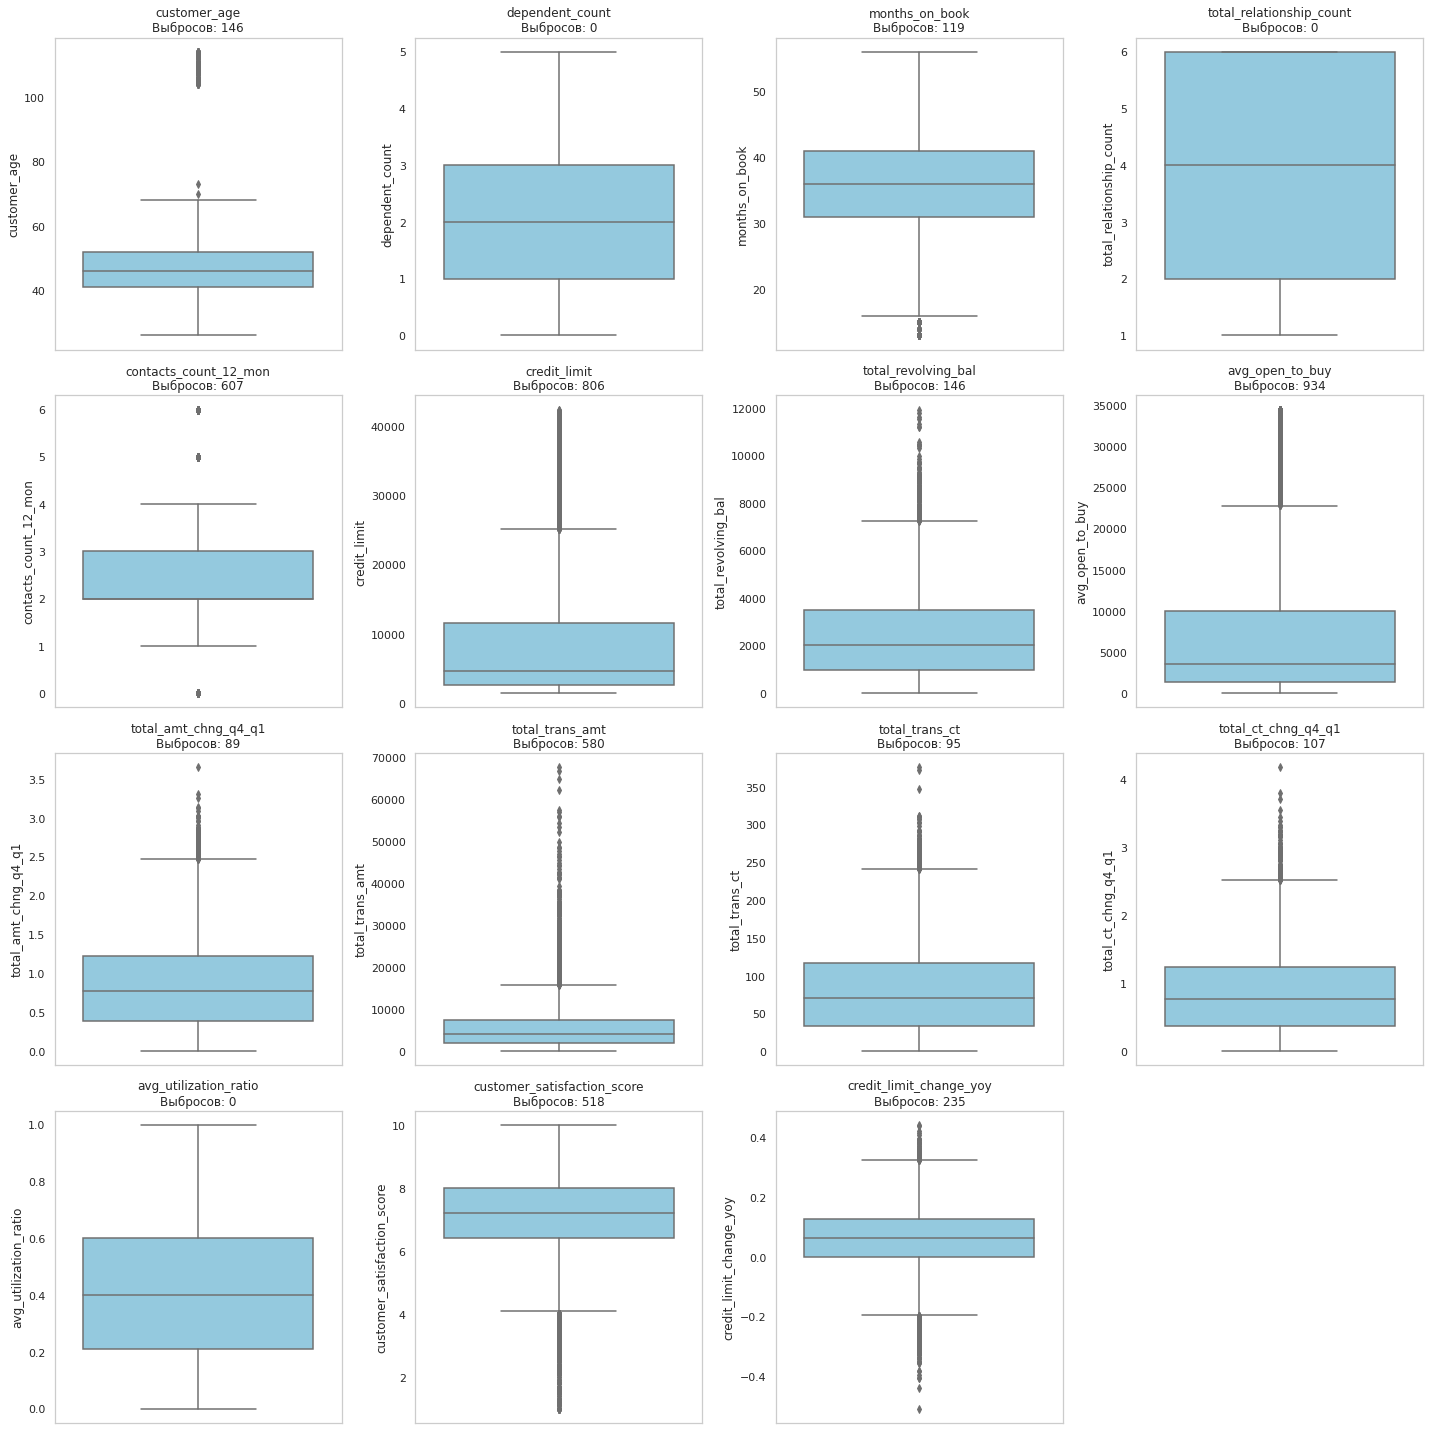

In [27]:
# 1. Формируем список колонок для анализа (исключаем target!)
cols_to_plot = [col for col in numeric_cols if col != 'target']

# 2. Настраиваем сетку графиков
# Если колонок много, лучше сделать сетку, а не 15 отдельных окон
n_cols = 4  # Количество колонок в сетке
n_rows = (len(cols_to_plot) + n_cols - 1) // n_cols

plt.figure(figsize = (20, 5 * n_rows))

for i, col in enumerate(cols_to_plot):
    plt.subplot(n_rows, n_cols, i + 1)
    
    # Строим boxplot
    sns.boxplot(y = df[col], color = 'skyblue')
    
    # Считаем выбросы по методу IQR (для подписи на графике)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Количество значений за пределами "усов"
    outliers_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    
    plt.title(f"{col}\nВыбросов: {outliers_count}")
    plt.ylabel(col)
    plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

Проанализируем распределения числовых признаков на наличие выбросов:

* Признак `customer_age` - возраст клиента, имеет выбросы (возраст некоторых клиентов превышает 100 лет). Это аномальные значения, их нужно удалить;
* Признаки `dependent_count`, `total_relationship_count`, `avg_utilization_ratio` не имеют выбросов. Распределение - нормальное;
* Признак `months_on_book` - количество месяцев, в течение которых клиент пользуется услугами банка. Выбросы в нижней части распределения — клиенты с коротким сроком обслуживания (новые клиенты). Для банка они — группа максимального риска. Выбросы оставляем;
* Признак `contacts_count_12_mon` - количество обращений в банк за последние 12 месяцев. Имеются выбросы в нижней и верхней частях распределения. Выбросы удалять нельзя: низкие значения (0–2) — это „спящие“ клиенты с высоким риском оттока, высокие — проблемные или сверхактивные клиенты, тоже критичные для прогноза;
* Признак `credit_limit` - установленный кредитный лимит (в долларах), имеет аномально высокие значения (от 25000 до более 40000). Скорее всего — это реальные лимиты VIP‑клиентов. Если их удалить, то можно потерять самый интересный сегмент, а модель научится предсказывать отток только для «обычных» клиентов. Выбросы оставляем;
* Признак `total_revolving_bal` - остаток задолженности по кредиту. Имеются выбросы от 7000 до более 12000 долларов. Это не мусор, а реальные клиенты с высокой долговой нагрузкой. И удалять их — значит потерять самую рисковую (и самую интересную для бизнеса) часть выборки. Выбросы оставляем;
* Признак `avg_open_to_buy` - средний доступный кредитный лимит. Имеются высокие значения от 23000 до 35000 долларов. Это лимиты VIP-клиентов. Выбросы оставляем;
* Признак `total_amt_chng_q4_q1` - показатель изменения суммы транзакций (отношение Q4 к Q1 кварталов). Имеют выбросы от 2,5 до более 3,5 - это не шум, а важные сигналы. Это может быть «финальный рывок» трат перед уходом или резкий всплеск активности — оба случая критичны для прогноза оттока. Удалять их нельзя: можно потерять самых рисковых клиентов.
* Признак `total_trans_amt` - общая сумма транзакций за год. Имеет выбросы от 15000 до 70000 долларов. Это не ошибки, а реальные траты активных или VIP‑клиентов;
* Признак `total_trans_ct` - общее количество транзакций за год. Имеет выбросы от 240 до более 350. Это не аномалии, а активные клиенты. Клиент с 300+ транзакциями — это «рабочая лошадка» банка. Он активно пользуется продуктом;
* Признак `total_ct_chng_q4_q1` - динамика изменения количества транзакций (отношение Q4 к Q1 кварталов). Имеет выбросы от 2,5 до более 4. Это клиенты с резким ростом активности: либо делают «финальный рывок» перед уходом, либо кардинально меняют поведение. Удалять их нельзя — так можно потерять самых рисковых клиентов;
* Признак `customer_satisfaction_score` - оценка удовлетворённости клиента сервисом. Имеются выбросы от 1 до 4.В распределении присутствует доля клиентов с низкой удовлетворённостью (оценки 1–4), что отражает реальную картину поляризации мнений, но не является статистическими выбросами, искажающими общую тенденцию. Это не ошибки, а реальные оценки клиентов;
* Признак `credit_limit_change_yoy` - изменение кредитного лимита за год. Может быть отрицательным (снижение — норма). Отрицательные значения - это не ошибка, а важный бизнес‑сигнал: резкое снижение лимита часто предшествует оттоку клиента. Эти значения очень важны для построения модели прогонирования оттока клиентов. Все значения оставляем.

**Задание 8.** Изучим получившиеся графики. Разделим признаки на два списка: те, которые мы будем чистить, и те, которые оставим как есть.

In [28]:
# Выведем список признаков, которые можно убрать из рассмотрения
columns_for_no_outlier_removal = ['dependent_count', 'total_relationship_count', 'months_on_book', 
                                  'contacts_count_12_mon', 'avg_utilization_ratio', 'credit_limit', 
                                  'avg_open_to_buy', 'total_revolving_bal', 'total_trans_amt', 
                                  'total_trans_ct', 'total_amt_chng_q4_q1', 'total_ct_chng_q4_q1',
                                  'customer_satisfaction_score', 'credit_limit_change_yoy']

# Выведемсписок колонок, которые стоит оставить для удаления выбросов
columns_for_outlier_removal = ['customer_age']

Что вообще означает наличие выбросов в целевой переменной (таргете)? На какую особенность выборки это может указывать?

Признак `target` - бинарная целевая переменная, у неё нет выбросов в классическом понимании. Это просто распределение классов. При анализе числовых признаков на выбросы этот признак исключим.

**Задание 9.** Очистим отобранные колонки от выбросов, используя классические границы: от Q1 − 1.5 * IQR до Q3 + 1.5 * IQR.

In [29]:
q3 = df['customer_age'].quantile(0.75)
iqr = df['customer_age'].quantile(0.75) - df['customer_age'].quantile(0.25)
threshold = q3 + 1.5 * iqr
df = df[df['customer_age'] <= threshold]

In [30]:
# Выведем статистику признака `customer_age` после удаления выбросов
df['customer_age'].describe()

count    9697.000
mean       46.307
std         8.000
min        26.000
25%        41.000
50%        46.000
75%        52.000
max        68.000
Name: customer_age, dtype: float64

Данные признака `customer_age` после удаления выбросов имеют нормальное распределение.

Как изменился размер вашего датафрейма после очистки? Как вы думаете, почему изменение оказалось именно таким (потеряли слишком много или, наоборот, мало строк)?



In [31]:
# Датасет до обработки выбросов
initial_rows = df_clean.shape[0]

# Датасет после обработки выбросов
final_rows = df.shape[0]

# Считаем количество удалённых строк
deleted_count = initial_rows - final_rows

# Процент удалённых
percent_deleted = (deleted_count / initial_rows) * 100

print(f'Исходное количество строк: {initial_rows}')
print(f'Количество строк после очистки: {final_rows}')
print(f'Удалено строк: {deleted_count}')
print(f'Процент удалённых строк: {percent_deleted:.3f}%') 

Исходное количество строк: 9843
Количество строк после очистки: 9697
Удалено строк: 146
Процент удалённых строк: 1.483%


После обработки выбросов количество строк в датасете уменьшилось примерно на 1,5%. Такое небольшое значение обусловлено тем, что понадобилось удалить выбросы только в столбце `customer_age`.

* Выведем датасет после  обработки выбросов.

In [32]:
df.head(5)

,client_id,customer_age,gender,dependent_count,education_level,marital_status,income_category,card_category,months_on_book,total_relationship_count,contacts_count_12_mon,credit_limit,total_revolving_bal,avg_open_to_buy,total_amt_chng_q4_q1,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,avg_utilization_ratio,customer_satisfaction_score,credit_limit_change_yoy,target
0,6b86b273ff34,45,M,3,high school,married,$60k - $80k,blue,39,6,3,12691.0,2381.914,11914.0,1.457,959.82,34,1.356,0.368,6.9,0.146,0
1,d4735e3a265e,49,F,5,graduate,single,less than $40k,blue,44,6,2,8256.0,1625.652,7392.0,1.399,4000.52,103,3.710,0.059,6.9,0.133,0
2,4e07408562be,51,M,3,graduate,married,$80k - $120k,blue,34,1,0,3418.0,368.070,3418.0,3.021,3826.00,40,1.268,0.393,8.0,0.107,0
3,ef2d127de37b,40,M,3,uneducated,married,unknown,blue,21,6,0,4716.0,1471.548,4716.0,2.201,372.71,13,2.642,0.042,7.2,-0.032,0
4,e7f6c011776e,44,M,2,graduate,married,$40k - $60k,blue,31,4,2,4010.0,2468.360,2763.0,1.395,6281.80,140,0.329,0.874,8.3,-0.018,0


In [33]:
df.shape

(9697, 22)

**ПРОМЕЖУТОЧНЫЙ ВЫВОД ПО РАЗДЕЛУ 2**

В ходе исследовательского анализа данных было выполнено:

1. Приведены названия столбцов-признаков к формату "snake case";
2. Для устранения неявных дубликатов, в категориальных признаках значения были приведены к нижнему регистру;
3. В категориальном признаке `gender` синонимы были приведены к единому формату (M/F);
4. Данные датасета были проверены на наличие явных дубликатов. Явные дубликаты отсутствуют;
5. Были выявлены дублирующиеся записи по уникальному идентификатору `client_id`. Для оценки масштаба проблемы был проведён детальный анализ пар дубликатов.

В ходе проверки установлено следующее: 
* Целевая переменная `Attrition_Flag` для всех пар дубликатов идентична (конфликтов типа «ушёл/остался» не обнаружено). 
* Различия между дубликатами наблюдаются лишь в незначительных числовых признаках (например, `avg_utilization_ratio`, `customer_satisfaction_score`), что указывает на техническую ошибку репликации данных, а не на изменение состояния клиента во времени (в датасете отсутствует временная метка, позволяющая интерпретировать строки как историю). 
* Наличие дубликатов искажает распределение признаков и приводит к переобучению модели, так как один и тот же клиент учитывается дважды.

**Решение**: Для устранения проблемы дубликаты были удалены с сохранением первого вхождения. Такой подход позволяет сохранить информацию о клиенте, исключив искажение статистики.

6. Для удобства анализа, целевая переменная `attrition_flag` заменена на бинарную целевую переменную `target`. Целевая переменная `attrition_flag` после замены, удалена;
7. При анализе распределения бинарной целевой переменной `target` был обнаружен явный дисбаланс. Банк обслуживает ~84% оставшихся клиентов, а ушедших всего ~16% (примерно 1:5).

Это опасно тем, что модель может «лениво» предсказывать только класс («0»), достигая Accuracy ≈ 84 %, но полностью игнорируя ушедших клиентов. Из‑за большего числа примеров класса «0» алгоритмы смещают веса в его пользу, ухудшая предсказание для целевого класса.

При дисбалансе `Accurac`y вводит в заблуждение. Для оценки алгоритмой необходимо использовать:
* **ROC‑AUC** — оценивает ранжирование по риску оттока (не зависит от порога);
* **F1‑Score (особенно Recall для класса «1»)** — важнее найти максимум ушедших, даже с риском ложных срабатываний;
* **Precision‑Recall Curve** — эффективнее ROC при малом числе положительных примеров.

Большинство алгоритмов в `sklearn` поддерживают параметр `class_weight='balanced'`. Он автоматически увеличивает вес ошибок на редком классе (ушедшие клиенты).

8. Пропуски были обнаружены: 

* В категориальном признаке признаке `income_category` (4%). Удаление строк привело бы к потере данных по другим признакам этих клиентов. Пропуски заменены на категорию 'unknown', чтобы модель могла выявить связанные с этим сегментом паттерны и их корреляцию с риском оттока клиентов;
* В числовых признаках `customer_satisfaction_score` (15.4%) и `credit_limit_change_yoy` (10.1%). Для заполнения пропусков выбрана медиана, как более устойчивая к потенциальным выбросам метрика, позволяющая сохранить центральную тенденцию признака без искажения профиля клиента. Удаление строк привело бы к потере данных по другим признакам этих клиентов.

Почему была выбрана мелиана: SGD чувствителен к экстремальным значениям. Заглушка даёт огромную ошибку и «взрывает» градиенты — модель может не сойтись. Медиана лежит в нормальном диапазоне, поэтому шаги оптимизации остаются плавными.

9. Был проведёны анализ и обработка аномальных значений. На основе диаграммы размаха, признаки были разделены на две категории:
* Признаки, которые не имеют выбросов;
* Признаки, у которых выбросы необходимо удалить (только признак `customer_age`). Данные признака `customer_age` после удаления выбросов имеют нормальное распределение.

Признак `target` - бинарная целевая переменная, у неё нет выбросов в классическом понимании. Это просто распределение классов. При анализе числовых признаков на выбросы этот признак исключим.

После обработки выбросов количество строк в датасете уменьшилось примерно на 1,5%. Такое небольшое значение обусловлено тем, что понадобилось удалить выбросы только в столбце `customer_age`.

Итоговый датасет после обработки выбросов состоит из 9697 строк и 22 признака.

## 3. Подготовка признаков<a class="anchor" id="chapter3"></a>

На этом этапе приведём «сырые» данные в формат, который максимально удобен для обучения алгоритмов. Будем работать с категориями и приводить числовые значения к единому масштабу.

### 3.1. Кодирование категориальных признаков

Машинам сложно работать с текстом напрямую, поэтому нам нужно перевести названия категорий в числа. Правильный выбор метода кодирования не только делает данные понятными для модели, но и помогает ей лучше находить скрытые закономерности.

Напомним основные типы категориальных признаков:

- Порядковые — категории, которые можно выстроить в логическую цепочку (например, уровень образования — от школы до докторской степени).
- Номинальные — категории, которые нельзя сравнить по принципу «больше или меньше» (например, семейное положение).
- Бинарные — признаки, имеющие всего два значения (например, пол).

Основные методы, которые применяют для кодирования признаков:
- One-Hot Encoding (OHE) — создаёт отдельные бинарные столбцы (0 или 1) для каждой категории.
- Label Encoding — заменяет категории порядковыми числами. Подходит для признаков с чёткой иерархией.
- Target Encoding — заменяет категорию средним значением целевой переменной. Помогает модели, но требует осторожности, чтобы не допустить утечки данных.

Не стоит использовать One-Hot Encoding для порядковых признаков. Это приведёт к потере информации об их иерархии, что может снизить качество модели.



**Задание 10.** Изучим категориальные признаки в датасете и определим для каждого из них подходящий тип и метод кодирования.

In [34]:
# Находим категориальные признаки в датасете
categorial_cols = df.select_dtypes(include = ['object', 'category']).columns.tolist()

print(f'Количество категориальных признаков: {len(categorial_cols)}.')
print(f'Список: {categorial_cols}.')

Количество категориальных признаков: 6.
Список: ['client_id', 'gender', 'education_level', 'marital_status', 'income_category', 'card_category'].


* Подберём для каждого категориального признака метод кодирования.

| Признак | Тип данных | Примеры значений | Метод кодирования | Обоснование выбора |
| :--- | :--- | :--- | :--- | :--- |
| `client_id` | Идентификатор | `1001`, `1002`, `1003` | Удалить (Drop) на этапе разделения выборок | Уникальный ID не несет информации о поведении клиента. Его использование приведет к переобучению. |
| `gender` | Категориальный (бинарный) | `M`, `F` | One-Hot Encoding | Нет естественного порядка. One-Hot создаст две бинарные колонки, понятные любой модели. |
| `education_level` | Категориальный (порядковый) | `uneducated`, `high school`, `college`, `graduate`,  `post-graduate`, `doctorate`, `unknown`   | Label Encoding (с ручным заданием порядка) | Есть явный порядок («Доктор» > «Бакалавр») |
| `marital_status` | Категориальный (номинальный) | `single`, `married`, `divorced`, `unknown` | One-Hot Encoding | Нет логичного порядка между статусами. One-Hot избежит навязывания ложной иерархии |
| `income_category` | Категориальный (порядковый) | `less than $40k`, `$40k - $60k`, `$60k - $80k`, `$80k - $120k`, `$120k +`, `unknown` | Label Encoding (с ручным заданием порядка) | Категории имеют четкий порядок по уровню дохода. Кодирование числами поможет модели увидеть тренд «чем выше доход, тем...». |
| `card_category` | Категориальный (номинальный) | `blue`, `gold`, `silver`, `platinum` | One-Hot Encoding | Хотя названия звучат как уровни, это разные продукты. Лучше не предполагать линейную зависимость между ними, если нет четкой бизнес-логики. |

**Задание 11.** Реализуем кодирование категориальных признаков выбранными методами.

In [35]:
# One-Hot Encoding
df = pd.get_dummies(df, columns = ['gender', 'marital_status', 'card_category'], drop_first = True, dtype = int)

In [36]:
# Label Encoding для `education_level`
education_order = ['uneducated', 'high school', 'college', 'graduate', 'post-graduate', 'doctorate', 'unknown']

education_map = {v: i for i, v in enumerate(education_order) if v != 'unknown'}
education_median = len(education_map) // 2
df['education_ordinal'] = df['education_level'].map(education_map).fillna(education_median)

In [37]:
# Label Encoding для `income_category`
income_order = ['less than $40k', '$40k - $60k', '$60k - $80k', '$80k - $120k', '$120k +', 'unknown']

income_map = {v: i for i, v in enumerate(income_order) if v != 'unknown'}
income_median = len(income_map) // 2
df['income_ordinal'] = df['income_category'].map(income_map).fillna(income_median)

* Удалим исходные признаки `education_level`, `income_category`.

In [38]:
df = df.drop(columns = ['education_level', 'income_category'], errors = 'ignore')

* Выведем первые строки датасета.

In [39]:
df.head(5)

,client_id,customer_age,dependent_count,months_on_book,total_relationship_count,contacts_count_12_mon,credit_limit,total_revolving_bal,avg_open_to_buy,total_amt_chng_q4_q1,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,avg_utilization_ratio,customer_satisfaction_score,credit_limit_change_yoy,target,gender_M,marital_status_married,marital_status_single,marital_status_unknown,card_category_gold,card_category_platinum,card_category_silver,education_ordinal,income_ordinal
0,6b86b273ff34,45,3,39,6,3,12691.0,2381.914,11914.0,1.457,959.82,34,1.356,0.368,6.9,0.146,0,1,1,0,0,0,0,0,1.0,2.0
1,d4735e3a265e,49,5,44,6,2,8256.0,1625.652,7392.0,1.399,4000.52,103,3.710,0.059,6.9,0.133,0,0,0,1,0,0,0,0,3.0,0.0
2,4e07408562be,51,3,34,1,0,3418.0,368.070,3418.0,3.021,3826.00,40,1.268,0.393,8.0,0.107,0,1,1,0,0,0,0,0,3.0,3.0
3,ef2d127de37b,40,3,21,6,0,4716.0,1471.548,4716.0,2.201,372.71,13,2.642,0.042,7.2,-0.032,0,1,1,0,0,0,0,0,0.0,2.0
4,e7f6c011776e,44,2,31,4,2,4010.0,2468.360,2763.0,1.395,6281.80,140,0.329,0.874,8.3,-0.018,0,1,1,0,0,0,0,0,3.0,1.0


* Выведем общую информацию датасета.

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 9697 entries, 0 to 9842
Data columns (total 26 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   client_id                    9697 non-null   object 
 1   customer_age                 9697 non-null   int64  
 2   dependent_count              9697 non-null   int64  
 3   months_on_book               9697 non-null   int64  
 4   total_relationship_count     9697 non-null   int64  
 5   contacts_count_12_mon        9697 non-null   int64  
 6   credit_limit                 9697 non-null   float64
 7   total_revolving_bal          9697 non-null   float64
 8   avg_open_to_buy              9697 non-null   float64
 9   total_amt_chng_q4_q1         9697 non-null   float64
 10  total_trans_amt              9697 non-null   float64
 11  total_trans_ct               9697 non-null   int64  
 12  total_ct_chng_q4_q1          9697 non-null   float64
 13  avg_utilization_ra

### 3.2. Масштабирование

Числовые признаки в датасете имеют разный размах: например, возраст измеряется десятками, а кредитный лимит — тысячами. Многие алгоритмы машинного обучения чувствительны к масштабу данных и могут ошибочно придать больший вес признакам с более крупными числами. Чтобы этого избежать, нам необходимо привести все числовые переменные к единому стандарту.

**Задание 12.** Используйте инструмент `StandardScaler` для числовых признаков, чтобы привести их к единому масштабу.

Важно: приступайте к масштабированию только после того, как полностью завершите очистку данных от выбросов и заполнение пропусков. Это поможет избежать искажений при подготовке модели.

Масштабирование не стоит применять до разделения на выборки. 

Когда происходит масштабирование по всему датасету до разбиения, статистика (среднее, дисперсия, минимум, максимум) считается по всем данным — в том числе по тем, которые потом попадут в тест. В результате модель косвенно «видит» тестовые данные ещё на этапе предобработки, и оценка её качества становится оптимистичной и нереалистичной.

Масштабирование будем проводить после разбиение данных на обучающую и тестовую выборки.

**ПРОМЕЖУТОЧНЫЙ ВЫВОД ПО РАЗДЕЛУ 3**

В ходе подготовки признаков к дальнейшему исследованию, было выполнено:

1. Кодирование категориальных признаков. Определены подходящие методы кодирования:

* One-Hot Encoding (OHE) — создаёт отдельные бинарные столбцы (0 или 1) для каждой категории (признаки `gender`, `marital_status`, `card_category`);
* Label Encoding — заменяет категории порядковыми числами. Подходит для признаков с чёткой иерархией (признаки `education_level` и `income_category`).

Реализовано кодирование категориальных признаков выбранными методами.

Исходные категориальные признаки  `education_level` и `income_category` удалены из датасета.

2. Масштабирование для числовых данных не стоит применять до разделения на выборки.

Масштабирование по всему датасету до разбиения приводит к утечке данных: статистика (среднее, дисперсия) учитывает тестовые данные, из‑за чего оценка качества модели становится нереалистично оптимистичной.

Масштабирование будем проводить после разбиение данных на обучающую и тестовую выборки.

Датасет после кодирования категориальных признаков состоит из 9697 строк и 26 признаков.

## 4. Анализ корреляции признаков<a class="anchor" id="chapter4"></a>

На этом этапе вы проверите, как признаки связаны между собой и с главной целью — оттоком. Корреляционный анализ важно проводить именно сейчас, когда данные уже очищены, пропуски заполнены, а категории переведены в числа.

Зачем это нужно:

- Чтобы найти признаки-дубликаты и убрать лишний «шум» из данных.
- Чтобы избежать мультиколлинеарности — ситуации, когда признаки слишком сильно зависят друг от друга, что делает модель нестабильной.
- Чтобы упростить модель — чем меньше избыточной информации, тем ниже риск переобучения и выше качество прогноза.




**Задание 13.** Рассчитаем матрицу корреляций с помощью метода `df.corr()` и построим тепловую карту (heatmap) с помощью библиотеки Seaborn.





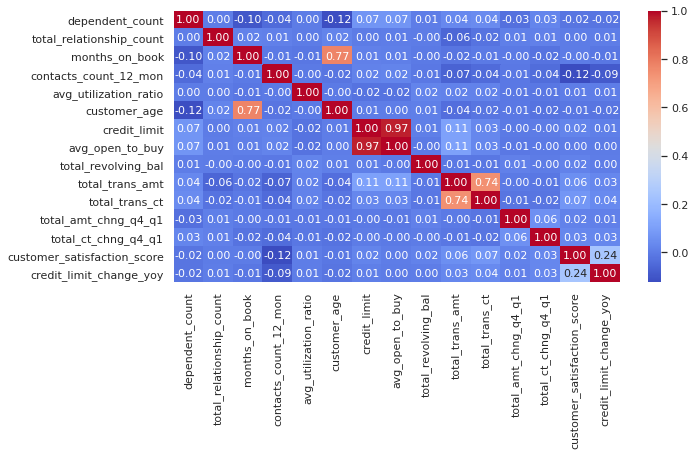

In [41]:
# Сформируем список с числовыми признаками
num_sign = ['dependent_count', 'total_relationship_count', 'months_on_book', 'contacts_count_12_mon', 'avg_utilization_ratio', 
            'customer_age', 'credit_limit', 'avg_open_to_buy', 'total_revolving_bal', 'total_trans_amt', 'total_trans_ct',
            'total_amt_chng_q4_q1', 'total_ct_chng_q4_q1', 'customer_satisfaction_score', 'credit_limit_change_yoy']

sns.heatmap(df[num_sign].corr(), annot = True, cmap = 'coolwarm', fmt = '.2f')
plt.show()

**Задание 14.** Найдём пары признаков с наиболее высокой корреляцией. Выгрузим их названия и значения коэффициентов.

In [42]:
# Берем только те колонки из твоего списка, которые реально есть в датасете
cols = [c for c in num_sign if c in df.columns]

# Считаем матрицу корреляций (Пирсон) и берем модуль (чтобы -0.9 и 0.9 считались одинаково сильными)
corr_matrix = df[cols].corr().abs()

# Оставляем только верхний треугольник матрицы (чтобы не было дублей: A-B и B-A)
# k=1 означает, что мы игнорируем диагональ (корреляцию признака с самим собой)
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Собираем пары, где корреляция > 0,7 (сильная связь)
pairs = []
for col in upper_triangle.columns:
    # Находим все признаки, сильно коррелирующие с текущим
    high_corr = upper_triangle[col][upper_triangle[col] > 0.7]
    for other_col, value in high_corr.items():
        pairs.append({
            'Первый признак': col,
            'Второй признак': other_col,
            'Коэффициент корреляции': round(value, 3)
        })

# Создаем DataFrame и сортируем от самой сильной связи к слабой
result_df = pd.DataFrame(pairs)
result_df = result_df.sort_values(by='Коэффициент корреляции', ascending=False)

# Вывод результата
display(result_df) 

,Первый признак,Второй признак,Коэффициент корреляции
1,avg_open_to_buy,credit_limit,0.973
0,customer_age,months_on_book,0.773
2,total_trans_ct,total_trans_amt,0.743


| Пара признаков | Что оставляем | Что убираем | Обоснование решения |
| :--- | :--- | :--- | :--- |
| `avg_open_to_buy` и `credit_limit` | **`credit_limit`** | `avg_open_to_buy` | Признак `avg_open_to_buy` является производной величиной (`Лимит - Долг`). Корреляция 0.973 указывает на критическую мультиколлинеарность. Оставляем базовый признак, так как он проще интерпретируется и не дублирует информацию. |
| `months_on_book` и `customer_age` | **Оба (рекомендуется)** или `customer_age` | — | Корреляция 0.773 отражает логическую связь (старшие клиенты чаще дольше в банке), но признаки несут разную смысловую нагрузку. Возраст — демография, стаж — история отношений. При необходимости сокращения оставляем `customer_age` как более фундаментальный показатель. |
| `total_trans_ct` и `total_trans_amt` | **`total_trans_amt`** | `total_trans_ct` | Сумма транзакций имеет большую бизнес-ценность и предсказательную силу. Количество транзакций частично дублирует информацию о сумме и менее значимо для оценки риска оттока. |

Для выявления мультиколлинеарности был установлен критический порог корреляции Пирсона на уровне 0,7.
Обоснование выбора порога: 
1. **Исключение дубликатов**: пороговое значение > 0,7 позволяет гарантированно удалить признаки, являющиеся производными друг от друга (например, `avg_open_to_buy` и `credit_limit`), что предотвращает нестабильность весов модели; 
2. **Баланс**: такой порог обеспечивает оптимальный баланс между упрощением модели и сохранением её предсказательной способности.

**Задание 15.** Удалим избыточные признаки из датасета с помощью `df.drop()`, чтобы очистить данные перед обучением модели.

In [43]:
df = df.drop(columns = ['avg_open_to_buy', 'months_on_book', 'total_trans_ct'], errors = 'ignore')

# Выведем первые строки датасета
df.head(5)

,client_id,customer_age,dependent_count,total_relationship_count,contacts_count_12_mon,credit_limit,total_revolving_bal,total_amt_chng_q4_q1,total_trans_amt,total_ct_chng_q4_q1,avg_utilization_ratio,customer_satisfaction_score,credit_limit_change_yoy,target,gender_M,marital_status_married,marital_status_single,marital_status_unknown,card_category_gold,card_category_platinum,card_category_silver,education_ordinal,income_ordinal
0,6b86b273ff34,45,3,6,3,12691.0,2381.914,1.457,959.82,1.356,0.368,6.9,0.146,0,1,1,0,0,0,0,0,1.0,2.0
1,d4735e3a265e,49,5,6,2,8256.0,1625.652,1.399,4000.52,3.710,0.059,6.9,0.133,0,0,0,1,0,0,0,0,3.0,0.0
2,4e07408562be,51,3,1,0,3418.0,368.070,3.021,3826.00,1.268,0.393,8.0,0.107,0,1,1,0,0,0,0,0,3.0,3.0
3,ef2d127de37b,40,3,6,0,4716.0,1471.548,2.201,372.71,2.642,0.042,7.2,-0.032,0,1,1,0,0,0,0,0,0.0,2.0
4,e7f6c011776e,44,2,4,2,4010.0,2468.360,1.395,6281.80,0.329,0.874,8.3,-0.018,0,1,1,0,0,0,0,0,3.0,1.0


In [44]:
df.shape

(9697, 23)

Как, по вашему мнению, отбор признаков на этапе оценки корреляции может повлиять на итоговый результат модели? Приведите пример (например, что произойдёт, если оставить два признака, которые по сути дублируют друг друга).

Если устранить мультиколлинеарность, модель становится стабильнее, интерпретируемее и точнее. Если оставить сильную зависимость между признаками — модель может «сломаться» или врать с метриками.

Например, если оставить в модели оба признака — `credit_limit` и `avg_open_to_buy` (с корреляцией 0,973) — произойдёт следующее:
* Для линейных моделей (Logistic Regression и др.): веса станут нестабильными и непредсказуемыми. Модель не сможет чётко определить вклад каждого признака: веса будут «скакать» при малейших изменениях данных, а интерпретация результатов станет бессмысленной;
* Для деревьев (Random Forest, XGBoost): исказится оценка важности признаков. Модель может «размазать» важность между двумя дублирующими колонками или случайно отдать приоритет одной из них, из‑за чего не будет понятно, какой фактор реально влияет на отток;
* Общий эффект: риск переобучения, снижение устойчивости модели и неверные бизнес‑выводы. Поэтому один из этих признаков (лучше `avg_open_to_buy`, как производный) нужно обязательно исключить.

**ПРОМЕЖУТОЧНЫЙ ВЫВОД ПО РАЗДЕЛУ 4**

В ходе анализа корреляции признаков было выявлена мультиколлинеарность у следующих числовых признаков:

| Первый признак | Второй признак | Коэффициент корреляции |
| :--- | :--- | :---: |
| avg_open_to_buy | credit_limit | 0.973 |
| customer_age | months_on_book | 0.773 |
| total_trans_ct | total_trans_amt | 0.743 |

Критический порог корреляции Пирсона установлен на уровне 0,7.

Обоснование: 

* Исключение дубликатов: порог > 0,7 позволяет удалить производные признаки (например, `avg_open_to_buy` и `credit_limit`), предотвращая нестабильность весов модели;
* Баланс: обеспечивает оптимальное соотношение между упрощением модели и сохранением предсказательной способности.

Были удалены избыточные признаки `avg_open_to_buy`, `months_on_book`, `total_trans_ct`, для устранения мультиколлинеарности. Так, модели станут более стабильными и веса не будут "скакать".

Итоговый датасет для этапа обучения моделей содержит 9697 строк и 23 столбца.

## 5. Обучение моделей и сравнение метрик<a class="anchor" id="chapter5"></a>

На данном этапе, разделим данных на обучающую и тестовую выборки, проведём преобразование данных, обучим алгоритмы и сравним метрики по результатам обучения.

**Задание 16.** Разделим данные на обучающую и тестовую выборки. 

Параметры для разделения:

* test_size = 0.3;
* random_state = 42. 

При разделении данных на выборки, дополнительно укажем параметр `stratify = y`. 

Клиентов, оставшихся в банке, заметно больше, чем ушедших, а стратификация позволит сохранить одинаковое соотношение классов в обучающей и тестовой выборках. Это сделает сравнение метрик более устойчивым и воспроизводимым.

In [45]:
# =========== КОНСТАНТЫ ПРОЕКТА ===========
RANDOM_STATE = 42       # Для воспроизводимости
TEST_SIZE = 0.3         # 30% на тест

In [46]:
# Разделяем датасет на признаки (матрица Х) и целевую переменную (y)
X = df.drop(columns = ['client_id', 'target'], axis = 1)
y = df['target']

# Разделяем данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = TEST_SIZE, random_state = RANDOM_STATE, stratify = y)

# Выведем размеры выборок в абсолютных значениях
print('Размеры выборок в абсолютных значениях:')
print(f'train_size: {X_train.shape} \ntest_size: {X_test.shape[0]}')

# Посчитаем размеры выборок в процентах
total_size = X.shape[0]
train_percentage = (X_train.shape[0] / total_size) * 100
test_percentage = (X_test.shape[0] / total_size) * 100

# Выведем размеры выборок в относительных значениях
print('\nРазмеры выборок в относительных значениях:')
print(f'train_percentage: {train_percentage:.2f}% \ntest_percentage: {test_percentage:.2f}%')

Размеры выборок в абсолютных значениях:
train_size: (6787, 21) 
test_size: 2910

Размеры выборок в относительных значениях:
train_percentage: 69.99% 
test_percentage: 30.01%


* Выделим числовые признаки для масштабирования.

In [47]:
# Числовые признаки
num_features = ['customer_age', 'dependent_count', 'total_relationship_count',
                'contacts_count_12_mon', 'avg_utilization_ratio', 'credit_limit', 
                'total_revolving_bal', 'total_trans_amt', 'total_amt_chng_q4_q1',
                'total_ct_chng_q4_q1', 'customer_satisfaction_score', 'credit_limit_change_yoy']

* Выполним масштабирование числовых признаков.

In [48]:
# Создаём объект масштабирования
scaler = StandardScaler()

# Применяем масштабирование на обучающую и тестовую выборки
X_train[num_features] = scaler.fit_transform(X_train[num_features])
X_test[num_features] = scaler.transform(X_test[num_features])

* Убедимся что масштабирование числовых признаков выполнено корректно.

In [49]:
print('--- Статистика после масштабирования (X_train) ---')
# Создаем DataFrame только с нужными колонками для наглядности
stats_train = pd.DataFrame({
    'mean': X_train[num_features].mean(),
    'std': X_train[num_features].std()
})

print(stats_train)

print('\n--- Статистика после масштабирования (X_test) ---')
stats_test = pd.DataFrame({
    'mean': X_test[num_features].mean(),
    'std': X_test[num_features].std()
})

print(stats_test)

--- Статистика после масштабирования (X_train) ---
                                  mean  std
customer_age                -3.120e-16  1.0
dependent_count              6.700e-17  1.0
total_relationship_count     1.152e-16  1.0
contacts_count_12_mon        8.846e-17  1.0
avg_utilization_ratio       -9.318e-17  1.0
credit_limit                 1.979e-16  1.0
total_revolving_bal          5.549e-17  1.0
total_trans_amt              2.110e-16  1.0
total_amt_chng_q4_q1        -3.952e-17  1.0
total_ct_chng_q4_q1          1.246e-16  1.0
customer_satisfaction_score -4.334e-16  1.0
credit_limit_change_yoy      2.408e-17  1.0

--- Статистика после масштабирования (X_test) ---
                              mean    std
customer_age                -0.005  1.000
dependent_count             -0.008  1.001
total_relationship_count    -0.014  1.009
contacts_count_12_mon        0.040  1.007
avg_utilization_ratio       -0.022  1.002
credit_limit                 0.011  0.991
total_revolving_bal         -0.0

**Задание 17.** Обучим обе модели `SGDClassifier` и `RandomForestClassifier`. Настроим параметры: начнём с базовых настроек, а затем меняем их и оцениваем, как это влияет на результат. 

Описания всех параметров можно найти в официальной документации к [SGDClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html) и [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

Для обучения возьмём два алгоритма: `SGDClassifier` и `RandomForestClassifier`. Сравним их работу по основным метрикам классификации: Accuracy, Precision, Recall и F1-score. Также построим график ROC-AUC, чтобы понять, насколько эффективно модели умеют различать лояльных и уходящих клиентов.

* Перечислим модели и настроим параметры для обучения.

In [50]:
# Инициализация
models = [
    SGDClassifier(max_iter = 1000,               # Максимальное число итераций обучения
                  learning_rate = 'constant',    # Шаг всегда остаётся одинаковым
                  eta0 = 0.0001,                 # Шаг
                  random_state = RANDOM_STATE,   # Генератор случайности
                  warm_start = False,             # Модель дообучается при поступлении новых данных
                  loss='log'                     # Для стабильности метрик
                 ), 
    RandomForestClassifier(
        random_state = RANDOM_STATE,             # Генератор случайности
        class_weight = 'balanced',               # Корректировка весов классов, при несбалансированных данных
        n_estimators = 500,                      # Количество деревьев
        n_jobs=-1                                # Количество вычислительных ядер процессора - все
    )
]

print('Модели успешно инициализированы!') 

Модели успешно инициализированы!


* Напишем функцию для обучения моделей и получения предсказаний.

In [51]:
def make_prediction_optimized(model, X_train, y_train, X_test, y_test): 
    
    """ Обучает модель, автоматически подбирает оптимальный порог отсечения 
    и возвращает полный набор результатов для анализа.
    Логика выбора порога: максимизация F1-score (баланс между Precision и Recall)."""
    
    # Обучаем модель на тренировочных данных
    model.fit(X_train, y_train)
    
    # Берем вероятность того, что клиент уйдёт (класс 1)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    # Перебираем пороги
    thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]
    
    print(f"\nАНАЛИЗ ВЛИЯНИЯ ПОРОГА ВЕРОЯТНОСТИ НА МЕТРИКИ ({model.__class__.__name__})")
    print("=" * 90)
    # Печатаем шапку таблицы
    print(f"{'Порог':<8} | {'Recall (поймано ушедших)':<28} | {'Precision (точность)':<22} | {'F1':<6}")
    print("-" * 90)
    
    # Поиск оптимального порога
    best_threshold = 0.5 
    best_f1 = -1 
    best_metrics = {} 
    best_y_pred = None
    
    print(f'Подбор оптимального порога для модели {model.__class__.__name__}...')
    
    for t in thresholds: 
        # Превращаем вероятности в классы: если >= порога -> 1 (уйдёт), иначе 0 
        y_pred_current = (y_prob >= t).astype(int)
    
        # Расчёт метрик для порогов
        accuracy = accuracy_score(y_test, y_pred_current)
        precision = precision_score(y_test, y_pred_current, pos_label = 1, average = 'binary')
        recall = recall_score(y_test, y_pred_current, pos_label = 1, average = 'binary')
        f1 = f1_score(y_test, y_pred_current, pos_label = 1, average = 'binary')
        
        print(f"{t:<8.1f} | {recall:.4f} ({recall * 100:.1f}%){' ' * 13} | {precision:.4f} ({precision * 100:.1f}%){' ' * 9} | {f1:.4f}")

        # Выбираем порог, дающий максимальный F1
        if f1 > best_f1: 
            best_f1 = f1 
            best_threshold = t 
            best_metrics = { 'accuracy': accuracy, 
                             'precision': precision, 
                             'recall': recall, 
                             'f1': f1 } 
            best_y_pred = y_pred_current
    
    # ROC-AUC показывает способность модели ранжировать клиентов независимо от порога 
    roc_auc = roc_auc_score(y_test, y_prob)
    best_metrics['roc_auc'] = roc_auc
    
    print(f"\nИТОГ ДЛЯ МОДЕЛИ: {model.__class__.__name__}") 
    print(f"Выбранный порог отсечения: {best_threshold}") 
    print(f"Accuracy (доля правильных ответов): {best_metrics['accuracy']:.3f}") 
    print(f"Precision (точность для ушедших): {best_metrics['precision']:.3f}") 
    print(f"Recall (полнота для ушедших): {best_metrics['recall']:.3f}") 
    print(f"F1 (баланс): {best_metrics['f1']:.3f}") 
    print(f"ROC-AUC (разделительная способность): {best_metrics['roc_auc']:.3f}") 
    print("-" * 60)
    
    # Матрица ошибок
    conf_matrix = confusion_matrix(y_test, best_y_pred)
    cm_df = pd.DataFrame(
        conf_matrix, 
        index=['Реально: Не ушёл (0)', 'Реально: Ушёл (1)'], 
        columns=['Предсказано: Не ушёл (0)', 'Предсказано: Ушёл (1)']
    )
    print('\nМатрица ошибок:')
    print(cm_df)
    
    # Интерпретация матрицы
    tn, fp, fn, tp = conf_matrix.ravel()
    total_churn = fn + tp  # Всего реально ушедших
    
    print("\nБИЗНЕС-ИНТЕРПРЕТАЦИЯ:")
    print(f"   ✅ Мы СПАСЛИ {tp} клиентов из {total_churn} (это {tp/total_churn*100:.1f}% ушедших).")
    print(f"   ❌ Мы ПРОПУСТИЛИ {fn} клиентов (они ушли, а мы не предупредили).")
    print(f"   ⚠️ Мы зря предложили скидку {fp} лояльным клиентам.")
    
    # Возврат всех данных для дальнейшей работы
    return {
        'model': model,                 # Обученная модель
        'threshold': best_threshold,   # Выбранный порог
        'y_pred': best_y_pred,         # Финальные предсказания (0/1)
        'y_prob': y_prob,              # Исходные вероятности (для графиков/анализа)
        'metrics': best_metrics,       # Словарь с метриками
        'confusion_matrix': conf_matrix # Матрица ошибок (числа)
    } 

* Применим функцию `make_prediction_optimized` к моделям.

In [52]:
results = {}

for current_model in models:
    model_name = current_model.__class__.__name__
    print(f"\n{'=' * 50}\nЗапуск модели: {model_name}\n{'=' * 50}")
    
    # Вызываем нашу умную функцию
    result = make_prediction_optimized(
        model=current_model,
        X_train=X_train,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test
    )
    
    # Сохраняем результат в словарь
    results[model_name] = result
    
    # Тут можно сразу вывести краткую сводку для таблицы
    m = result['metrics']
    print(f"\n>>> {model_name}: Порог={result['threshold']}, Recall={m['recall']:.3f}, F1={m['f1']:.3f}")


Запуск модели: SGDClassifier

АНАЛИЗ ВЛИЯНИЯ ПОРОГА ВЕРОЯТНОСТИ НА МЕТРИКИ (SGDClassifier)
Порог    | Recall (поймано ушедших)     | Precision (точность)   | F1    
------------------------------------------------------------------------------------------
Подбор оптимального порога для модели SGDClassifier...
0.5      | 0.6208 (62.1%)              | 0.8395 (84.0%)          | 0.7138
0.4      | 0.6907 (69.1%)              | 0.7743 (77.4%)          | 0.7301
0.3      | 0.7797 (78.0%)              | 0.6619 (66.2%)          | 0.7160
0.2      | 0.8644 (86.4%)              | 0.5231 (52.3%)          | 0.6518
0.1      | 0.9301 (93.0%)              | 0.3584 (35.8%)          | 0.5174

ИТОГ ДЛЯ МОДЕЛИ: SGDClassifier
Выбранный порог отсечения: 0.4
Accuracy (доля правильных ответов): 0.917
Precision (точность для ушедших): 0.774
Recall (полнота для ушедших): 0.691
F1 (баланс): 0.730
ROC-AUC (разделительная способность): 0.931
------------------------------------------------------------

Матрица ошиб

В ходе сравнительного анализа моделей для задачи прогнозирования оттока (Churn Prediction) была выбрана модель **RandomForestClassifier**. 

Несмотря на незначительно более низкий показатель Recall (71.2 % против 69.1 % у SGD), RandomForest демонстрирует лучшие значения ключевых метрик: F1‑score (0.767 против 0.730) и Precision (83.2 % против 77.4 %).

Это свидетельствует о более сбалансированной работе модели и её способности эффективнее ранжировать клиентов, минимизируя нецелевое расходование ресурсов на удержание лояльных пользователей. Значение ROC‑AUC, равное 0.945, подтверждает высокую разделительную способность модели.

Таким образом, RandomForest является оптимальным решением для внедрения в бизнес‑процесс с учётом ограничений бюджета на маркетинговые кампании.

В сценариях с высокой стоимостью ошибки пропуска клиента (например, работа с VIP‑сегментом, где потеря одного клиента эквивалентна значительным финансовым убыткам) приоритет смещается с максимизации Precision на максимизацию Recall. В таких условиях модель SGDClassifier, демонстрирующая более высокий Recall при снижении Precision, может быть предпочтительнее. 

Несмотря на рост числа нецелевых коммуникаций, данный подход оправдан экономически: предотвращение оттока даже части 
высокодоходных клиентов компенсирует затраты на адресные предложения остальным. Ключевым условием применимости такой стратегии является ситуация, когда стоимость ложной тревоги существенно ниже стоимости упущенной выгоды от потери клиента.

**Задание 18.** Постройте ROC-AUC кривую для той модели, которую вы выбрали как лучшую, и проинтерпретируйте результат.

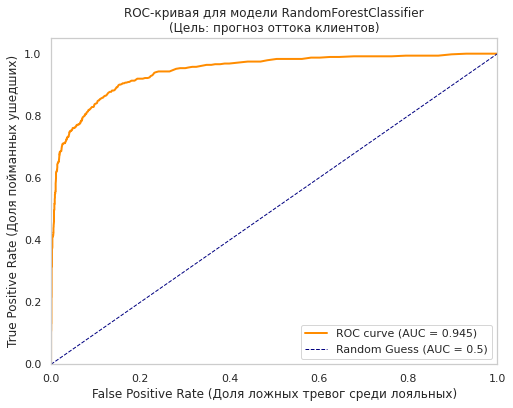

In [53]:
# Берем лучшую модель (RandomForest)
best_model_name = 'RandomForestClassifier'
best_result = results[best_model_name]

# Получаем истинные значения и вероятности оттока
y_true = y_test
y_prob = best_result['y_prob']  # Это вероятности класса 1 ('ушёл')

# Считаем точки для ROC-кривой
# fpr: False Positive Rate (доля ошибочно предсказанных ушедших среди оставшихся)
# tpr: True Positive Rate (доля верно предсказанных ушедших среди всех ушедших)
# thresholds: пороги отсечения
fpr, tpr, thresholds = roc_curve(y_true, y_prob)

# Считаем площадь под кривой (AUC)
roc_auc = auc(fpr, tpr)

# Строим график
plt.figure(figsize = (8, 6))
plt.plot(fpr, tpr, color = 'darkorange', lw = 2, label = f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color = 'navy', lw = 1, linestyle = '--', label = 'Random Guess (AUC = 0.5)')

# Оформление
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Доля ложных тревог среди лояльных)')
plt.ylabel('True Positive Rate (Доля пойманных ушедших)')
plt.title(f'ROC-кривая для модели {best_model_name}\n(Цель: прогноз оттока клиентов)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

Модель работает значительно лучше случайного угадывания (0.5).

**ПРОМЕЖУТОЧНЫЙ ВЫВОД ПО РАЗДЕЛУ 5**

1. Обработанные данные датасета были разделены на обучающую (70 %) и тестовую выборки (30 %). 

Дополнительно, был указан параметр `stratify = y` с целью сохранения одинакового соотношения классов в обучающей и тестовой выборках.

2. После разделения данных на обучающую и тестовую выборки, было проведено масштабирование числовых признаков.

3. Создан список моделей для обучения `SGDClassifier` и `RandomForestClassifier` с параметрами.

4. Написана функция для обучения моделей с перебором порогов и получения предсказаний.

Для оптимизации качества модели был реализован подход с перебором порогов отсечения вероятностей: (0.5, 0.4, 0.3, 0.2, 0.1).

Для каждого порога рассчитывались метрики Precision, Recall и F1-score. В качестве критерия выбора оптимального порога была выбрана максимизация F1-score, позволяющего учесть баланс между полнотой и точностью предсказаний.

В результате анализа установлено, что порог t = 0.4 обеспечивает наилучшее соотношение метрик для обеих моделей. 

| Модель | Порог | Accuracy | Recall (Спасено клиентов) | Precision (Точность) | F1-Score | ROC-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| SGDClassifier | 0.4 | 91.7% | 69.1% (326 чел.) | 77.4% | 0.730 | 0.931 |
| **RandomForestClassifier** | **0.4** | **93.0%** | **71.2% (336 чел.)** | **83.2%** | **0.767** | **0.945** |

При пороге 0.4 значение Recall возрастает до ~70 % (что позволяет охватить значительную долю уходящих клиентов), сохраняя при этом высокий уровень Precision.
Дальнейшее снижение порога (например, до 0.2 или 0.1), несмотря на рост Recall, приводило к резкому падению Precision и увеличению количества нецелевых маркетинговых коммуникаций. Это экономически нецелесообразно: затраты на скидки лояльным клиентам начали бы превышать выгоду от удержания ушедших.

По результатам анализа выбираем модель **RandomForestClassifier с порогом t=0.4**:

* **Лучший баланс (F1‑Score)**: у RandomForest — 0.767, у SGD — 0.730. F1 — главная метрика для несбалансированных данных: она штрафует модель и за пропуск уходящих клиентов, и за лишние предложения скидок. RandomForest справляется с этим лучше, показывая более устойчивый баланс ошибок.
* **Выше точность (Precision)**: 83.2 % против 77.4 %. Это значит, что из 100 клиентов, которым RandomForest предложит скидку, реально уйдут примерно 83 человека. У SGD — только 77. Для бизнеса это экономия бюджета: мы тратим деньги на удержание более осмысленно, снижая долю нецелевых коммуникаций.
* **Лучшее ранжирование (ROC‑AUC)**: 0.945 против 0.931. RandomForest увереннее расставляет клиентов по «шкале риска» — кто точно уйдёт, а кто останется. Значение ROC‑AUC, равное 0.945, подтверждает высокую разделительную способность модели: она отлично отделяет «рискованных» клиентов от лояльных даже без учёта порога.
* **Хороший охват (Recall)**: RandomForest ловит 71.2 % ушедших клиентов (336 человек из 472). Да, при снижении порога можно было бы поймать чуть больше, но эта разница не стоит потери точности. Лучше спасти 71.2 % клиентов с высокой уверенностью (Precision 83.2 %), чем пытаться поймать 80–90 %, но при этом зря предлагать скидки трети лояльной базы — это экономически нецелесообразно.

5. Построена ROC‑AUC кривая для модели RandomForestClassifier с порогом t=0.4.
AUC = 0.945 означает, что модель обладает отличной способностью различать классы. Это существенно выше уровня случайного угадывания (0.5) и близко к идеальному значению (1.0). Для задачи прогнозирования оттока такой результат говорит о том, что модель уверенно выделяет группу риска даже на зашумлённых данных.

## 6. Анализ важности признаков<a class="anchor" id="chapter6"></a>

Для некоторых алгоритмов, таких как случайный лес (Random Forest), мы можем посмотреть «внутрь» модели и понять, на что она опиралась при прогнозировании. Оценка важности признаков (Feature Importance) полезна как для дополнительного отбора самых сильных метрик при разработке модели, так и для общения с заказчиком. Такие результаты легко интерпретируются бизнесом и помогают наглядно объяснить причины ухода клиентов.  

**Задание 19.** Оценим важность признаков для обученной модели `RandomForestClassifier` с помощью встроенного атрибута `feature_importances_`. Визуализируем результат: построим горизонтальную столбчатую диаграмму для топ-10 самых значимых признаков (например, с помощью метода `df.plot(kind='barh')`).

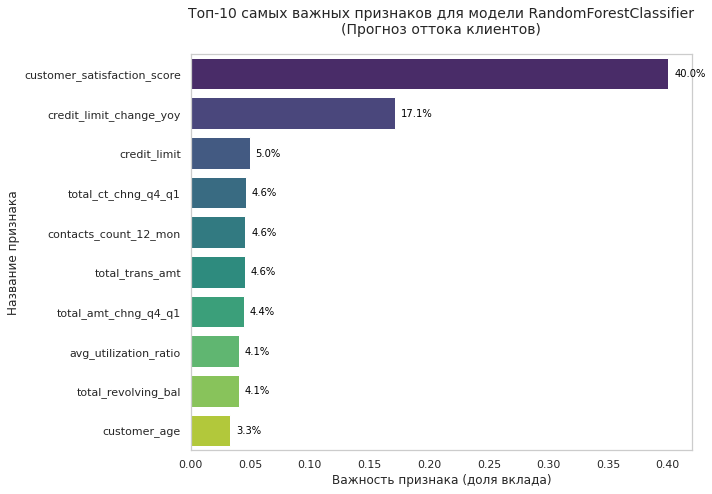

In [65]:
# Получаем данные (берем словаря results)
model_name = 'RandomForestClassifier'
rf_model = results[model_name]['model']
feature_names = X_train.columns
importances = rf_model.feature_importances_

# Создаем DataFrame и сортируем
feat_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})
top_10_features = feat_importance.sort_values(by = 'Importance', ascending = False).head(10)

# Настройка графика
plt.figure(figsize=(10, 7))
ax = sns.barplot(data=top_10_features, x = 'Importance', y = 'Feature', palette='viridis')

plt.title(f'Топ-10 самых важных признаков для модели {model_name}\n(Прогноз оттока клиентов)', fontsize = 14, pad = 20)
plt.xlabel('Важность признака (доля вклада)', fontsize = 12)
plt.ylabel('Название признака', fontsize = 12)
plt.grid(axis = 'x', linestyle = '--', alpha = 0.7)

# Добавляем подписи значений на столбцы
for i, v in enumerate(top_10_features['Importance']):
    # ax.patches[i] - это i-й столбец
    # get_width() - длина столбца
    # get_y() + get_height()/2 - центр столбца по вертикали
    
    # Форматируем число: умножаем на 100 и берем 2 знака после запятой
    label_text = f"{v*100:.1f}%"
    
    # Добавляем текст справа от столбца
    ax.text(
        v + 0.005,  # X: немного правее конца столбца (отступ 0.005)
        i,          # Y: индекс строки (i)
        label_text, # Текст
        va='center',# Вертикальное выравнивание: по центру
        fontsize=10,
        color='black'
    )

plt.tight_layout()
plt.show()

* Найдём направление связи ключевых признаков `customer_satisfaction_score`, `credit_limit_change_yoy` с оттоком (средние значения по группам).

In [64]:
df.groupby('target')[['customer_satisfaction_score', 'credit_limit_change_yoy']].mean()

,customer_satisfaction_score,credit_limit_change_yoy
target,,
0,7.448,0.080
1,4.935,-0.037


**ПРОМЕЖУТОЧНЫЙ ВЫВОД ПО РАЗДЕЛУ 6**

Для понимания логики работы выбранной модели RandomForestClassifier был проведён анализ важности признаков. Результаты показали, что модель опирается на понятные бизнес‑метрики, а не на «шум».

| Признак | Важность | Бизнес‑интерпретация | Действие для удержания |
| :--- | :---: | :--- | :--- |
| `customer_satisfaction_score` | **40%** | Главный предиктор. Низкая оценка удовлетворённости — сильнейший сигнал о намерении уйти. | Приоритет №1: работа с обратной связью, быстрое решение жалоб, персональный менеджер для недовольных. |
| `credit_limit_change_yoy` | **17.1%** | Резкое снижение лимита воспринимается как потеря доверия банка. Вызывает стресс даже у платёжеспособных клиентов. | Коммуникация: объяснять причину снижения лимита и предлагать альтернативы (рефинансирование, другие продукты). |
| `credit_limit` | **5.0%** | Размер лимита коррелирует с ценностью клиента и его ожиданиями от сервиса. | Сегментация: предлагать индивидуальные условия в зависимости от лимита. |
| `total_trans_amt`, `total_ct_chng_q4_q1`, `contacts_count_12_mon` | 4.6% | Падение оборотов, количества транзакций, количества контактов с банком в течении 12 месяцев — ранний признак снижения активности. | Триггерные предложения: «Заметили, что вы реже пользуетесь картой — вот персональное предложение». |
|`total_amt_chng_q4_q1`| 4.4% | Резкое снижение суммы транзакций от Q1 к Q4 — сигнал о потере интереса к продукту или переходе на карты другого банка. Если показатель сильно падает - это тревожный маркер. | Проактивная коммуникация: предложить повышенный кэшбэк или бонусы за возобновление активности; проверить, не возникли ли технические проблемы (например, блокировка карты). |
| `total_revolving_bal`, `avg_utilization_ratio` | 4.1% | Клиенты с высокой долговой нагрузкой более чувствительны к изменениям условий. | Аккуратные коммуникации; фокус на снижении нагрузки (реструктуризация), а не на новых кредитах. |
| `customer_age` | **3.3%** | Умеренное влияние. Отток определяется поведением, а не демографией. | Не делать сегментацию только по возрасту; фокусироваться на поведенческих сигналах. |

На оценку удовлетворённости приходится 40% важности признаков в модели, вместе с изменением лимита — 57%.

Таблица средних значений по статусу клиента дополняет картину: она показывает не только силу влияния признаков, но и направление связи. Например, низкая удовлетворённость и снижение кредитного лимита напрямую ассоциированы с более высокой вероятностью ухода. 

Такой подход позволяет сместить фокус маркетинговых кампаний с «массовых скидок» на «точечное решение проблем».

## 7. Финальные предсказания<a class="anchor" id="chapter7"></a>

Вы вышли на финишную прямую: модель обучена, её метрики на хорошем уровне. Теперь нужно получить итоговые прогнозы, которые можно будет передать бизнесу. На этом этапе важно получить не просто категорию «уйдет или останется», а именно вероятность оттока для каждого клиента. Это позволит отделу удержания точнее расставлять приоритеты в своей работе.  

**Задание 20.** Сделаем предсказания на тестовой выборке. Используем метод, который возвращает вероятности (`predict_proba()`), и сохраним результат в новый датафрейм. 

В итоговой таблице должны быть две колонки: уникальный идентификатор клиента
(`Client_ID`) и рассчитанная вероятность (`Predicted_Churn_Prob`).

In [55]:
# Берём лучшую модель из наших результатов
best_model_name = 'RandomForestClassifier'
best_model = results[best_model_name]['model']

# Получаем вероятности оттока (класс 1) для тестовой выборки
final_preds = best_model.predict_proba(X_test)[:, 1]

# Восстанавливем client_id через индексы
# Логика: X_test.index содержит номера строк из исходного df.
# Мы берем эти строки из исходного df (или df_test, где есть ID) и вытаскиваем колонку client_id
client_ids = df.loc[X_test.index, 'client_id']

# Создаём итоговый датафрейм
output = pd.DataFrame({
    'client_id': client_ids,
    'predicted_churn_prob': final_preds
})

# Сортируем по убыванию вероятности
output = output.sort_values(by = 'predicted_churn_prob', ascending=False)

# Сбрасываем индекс
output = output.reset_index(drop = True)

# Выводим первые 10 строк для проверки
print("Топ-10 клиентов с самым высоким риском оттока:\n")
print(output.head(10))
print(output.shape)

Топ-10 клиентов с самым высоким риском оттока:

      client_id  predicted_churn_prob
0  214c993d16c6                 0.960
1  3c06bc19eae1                 0.956
2  83f16a7746e6                 0.956
3  fd69b53f644e                 0.954
4  788181d3e6c4                 0.952
5  74ed65a2d22a                 0.952
6  9934db2d9075                 0.948
7  584e6896455d                 0.948
8  c2db26c514cd                 0.942
9  b3e23bcee2cc                 0.940
(2910, 2)


**Задание 21.** Построим гистограмму распределения клиентов по вероятности оттока. Изучим получившийся график и проинтерпретируем результат: насколько чётко модель разделяет клиентов на группы и много ли людей оказалось в зоне риска?

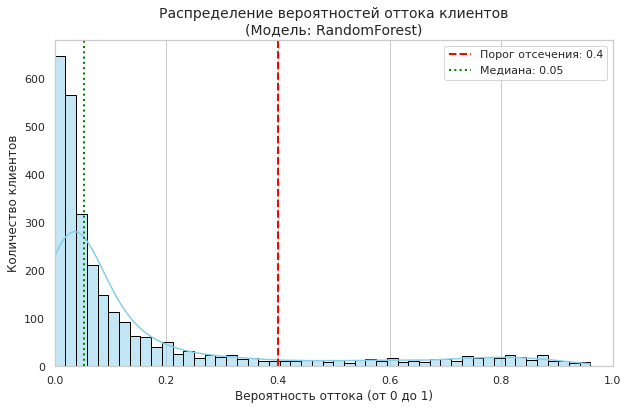

СТАТИСТИКА РАСПРЕДЕЛЕНИЯ ВЕРОЯТНОСТЕЙ
Мин. вероятность: 0.0000
Макс. вероятность: 0.9600
Среднее значение: 0.1583
Медиана: 0.0520
------------------------------------------------------------
Зона НИЗКОГО риска (< 0.4): 2506 клиентов (86.1%)
Зона СРЕДНЕГО риска (0.4–0.5): 63 клиентов (2.2%)
Зона ВЫСОКОГО риска (> 0.5): 341 клиентов (11.7%)


In [56]:
# Берём вероятности из нашего итогового датафрейма 'output'
probs = output['predicted_churn_prob']

plt.figure(figsize=(10, 6))

# Строим гистограмму с плотностью (чтобы площадь под графиком была равна 1)
sns.histplot(probs, bins = 50, kde = True, color = 'skyblue', edgecolor = 'black')

# Добавляем вертикальную линию для нашего порога отсечения (0.4)
plt.axvline(x = 0.4, color = 'red', linestyle = '--', linewidth = 2, label = f'Порог отсечения: 0.4')

# Добавляем линии для квантилей (опционально, чтобы видеть, где середина)
plt.axvline(x = probs.median(), color = 'green', linestyle = ':', linewidth = 2, label = f'Медиана: {probs.median():.2f}')

plt.title('Распределение вероятностей оттока клиентов\n(Модель: RandomForest)', fontsize = 14)
plt.xlabel('Вероятность оттока (от 0 до 1)', fontsize = 12)
plt.ylabel('Количество клиентов', fontsize = 12)
plt.legend(loc = 'upper right')
plt.grid(axis = 'y', alpha = 0.3, linestyle = '--')
plt.xlim(0, 1) # Ограничиваем ось X от 0 до 1

plt.show()

# --- Дополнительная статистика для отчета ---
print("=" * 60)
print("СТАТИСТИКА РАСПРЕДЕЛЕНИЯ ВЕРОЯТНОСТЕЙ")
print("=" * 60)
print(f"Мин. вероятность: {probs.min():.4f}")
print(f"Макс. вероятность: {probs.max():.4f}")
print(f"Среднее значение: {probs.mean():.4f}")
print(f"Медиана: {probs.median():.4f}")
print("-" * 60)

# Считаем, сколько клиентов в разных зонах
zone_low = probs[probs < 0.4].count()
zone_mid = probs[(probs >= 0.4) & (probs <= 0.5)].count()
zone_high = probs[probs > 0.5].count()
total = len(probs)

print(f"Зона НИЗКОГО риска (< 0.4): {zone_low} клиентов ({zone_low/total*100:.1f}%)")
print(f"Зона СРЕДНЕГО риска (0.4–0.5): {zone_mid} клиентов ({zone_mid/total*100:.1f}%)")
print(f"Зона ВЫСОКОГО риска (> 0.5): {zone_high} клиентов ({zone_high/total*100:.1f}%)")
print("="*60)

Распределение предсказанных вероятностей подтверждает реалистичность и экономическую эффективность модели:
* 86,1 % клиентов (2506 человек) попадают в зону низкого риска. Для этой группы активные меры удержания не требуются, что позволяет существенно экономить маркетинговый бюджет и не раздражать лояльных клиентов лишними предложениями.
* 13,9 % клиентов формируют целевую аудиторию для работы:
    * 11,7 % (341 человек) — зона высокого риска (> 0,5). Это приоритетная группа, где усилия по удержанию принесут максимальную отдачу.
    * 2,2 % (63 человека) — пограничная зона (0,4–0,5). Эту небольшую группу можно использовать для тестирования мягких предложений или усиленного мониторинга.

**ПРОМЕЖУТОЧНЫЙ ВЫВОД ПО РАЗДЕЛУ 7**

В ходе финального анализа были получены прогнозные вероятности оттока для тестовой выборки. Распределение вероятностей носит асимметричный характер, что соответствует природе задачи Churn Prediction: отток является редким событием, и большинство клиентов демонстрируют стабильное поведение.

Статистический анализ показал, что подавляющее большинство клиентов (86,1 %, или 2506 человек) имеют низкую вероятность ухода (< 0,4). Это свидетельствует о стабильности основной клиентской базы и подтверждает, что модель не склонна к ложной тревоге.

При этом, модель успешно выделила группу риска: 13,9 % клиентов (404 человека) демонстрируют повышенную склонность к оттоку. Из них 341 клиентов (11,7 % от всей выборки) попадают в зону высокого риска (вероятность > 0,5) — это приоритетная аудитория для маркетинговых акций.

Особое внимание заслуживают клиенты с максимальной вероятностью оттока: максимальное значение достигает 0,96, что говорит о высокой уверенности модели в прогнозе для отдельных кейсов.

На основании распределения вероятностей и рассчитанных метрик (F1 = 0,767, Precision = 83,2 %) был обоснован выбор порога отсечения 0,4. Такой порог позволяет эффективно охватить значительную часть рискованной аудитории, сохраняя высокую точность прогноза. При этом модель спасает 71,2 % ушедших клиентов (336 человек), минимизируя количество нецелевых коммуникаций.

##  8. Выводы и рекомендации для бизнеса<a class="anchor" id="chapter8"></a>

Целью проекта являлось построение модели бинарной классификации, которая спрогнозирует вероятность оттока каждого клиента в следующем месяце.

Проект был разделён на следующие этапы:

1. **Загрузка и предварительный просмотр данных**

Исходный датасет содержит 9852 строк и 24 столбца, в которых представлена информация о клиентах банка "ФинПрогресс".

Типы данных соответствуют информации и пригодны для анализа.

Проведён сравнительный анализ медиан и средних значений для числовых столбцов-признаков.

Были выявлены и удалены признаки, которые потенциально могут вызвать утечку данных при обучении алгоримов: `Online_Logins_12_mon`, `Days_Since_Last_Contact`.

2. **EDA — разведочный анализ**

* Приведены названия столбцов-признаков к формату "snake case";
* Для устранения неявных дубликатов, в категориальных признаках значения были приведены к нижнему регистру;
* В категориальном признаке `gender` синонимы были приведены к единому формату (M/F);
* Данные датасета были проверены на наличие явных дубликатов. Явные дубликаты отсутствуют;
* Были выявлены дублирующиеся записи по уникальному идентификатору `client_id`. Для оценки масштаба проблемы был проведён детальный анализ пар дубликатов. Наличие неявных дубликатов искажает распределение признаков и приводит к переобучению модели, так как один и тот же клиент учитывается дважды. Для устранения проблемы дубликаты были удалены с сохранением первого вхождения. Такой подход позволяет сохранить информацию о клиенте, исключив искажение статистики;
* Для удобства анализа, целевая переменная `attrition_flag` заменена на бинарную целевую переменную `target`. Целевая переменная `attrition_flag` после замены, удалена;
* При анализе распределения бинарной целевой переменной `target` был обнаружен явный дисбаланс. Банк обслуживает ~84% оставшихся клиентов, а ушедших всего ~16% (примерно 1:5).
* Пропуски были обнаружены: 
    * В категориальном признаке признаке `income_category` (4%). Удаление строк привело бы к потере данных по другим признакам этих клиентов. Пропуски заменены на категорию 'unknown', чтобы модель могла выявить связанные с этим сегментом паттерны и их корреляцию с риском оттока клиентов;
    * В числовых признаках `customer_satisfaction_score` (15.4%) и `credit_limit_change_yoy` (10.1%). Для заполнения пропусков выбрана медиана, как более устойчивая к потенциальным выбросам метрика, позволяющая сохранить центральную тенденцию признака без искажения профиля клиента. Удаление строк привело бы к потере данных по другим признакам этих клиентов.

Почему была выбрана медиана: SGD чувствителен к экстремальным значениям. Заглушка даёт огромную ошибку и «взрывает» градиенты — модель может не сойтись. Медиана лежит в нормальном диапазоне, поэтому шаги оптимизации остаются плавными.

* Был проведён анализ и обработка аномальных значений. На основе диаграммы размаха, признаки были разделены на две категории:
    * Признаки, которые не имеют выбросов;
    * Признаки, у которых выбросы необходимо удалить (только признак `customer_age`). Данные признака `customer_age` после удаления выбросов имеют нормальное распределение.

После обработки выбросов количество строк в датасете уменьшилось примерно на 1,5%. Такое небольшое значение обусловлено тем, что понадобилось удалить выбросы только в столбце `customer_age`.

3. **Подготовка признаков**

* Проведено кодирование категориальных признаков. Исходные категориальные признаки  `education_level` и `income_category` удалены из датасета;
* Масштабирование решено проводить после разбиение данных на обучающую и тестовую выборки, так как масштабирование по всему датасету до разбиения приводит к утечке данных.

4. **Анализ корреляции признаков**

Критический порог корреляции Пирсона установлен на уровне 0,7.

Были удалены избыточные признаки `avg_open_to_buy`, `months_on_book`, `total_trans_ct`, для устранения мультиколлинеарности. Так, модели станут более стабильными и веса не будут "скакать".

Итоговый датасет для этапа обучения моделей содержит 9697 строк и 23 столбца.

5. **Обучение моделей и сравнение метрик**

* Обработанные данные датасета были разделены на обучающую (70 %) и тестовую выборки (30 %). Дополнительно, был указан параметр `stratify = y` с целью сохранения одинакового соотношения классов в обучающей и тестовой выборках;
* После разделения данных на обучающую и тестовую выборки, было проведено масштабирование числовых признаков;
* Создан список моделей для обучения `SGDClassifier` и `RandomForestClassifier` с параметрами;
* Написана функция для обучения моделей с перебором порогов и получения предсказаний.

Для оптимизации качества модели был реализован подход с перебором порогов отсечения вероятностей: (0.5, 0.4, 0.3, 0.2, 0.1).

| Модель | Порог | Accuracy | Recall (Спасено клиентов) | Precision (Точность) | F1-Score | ROC-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| SGDClassifier | 0.4 | 91.7% | 69.1% (326 чел.) | 77.4% | 0.730 | 0.931 |
| **RandomForestClassifier** | **0.4** | **93.0%** | **71.2% (336 чел.)** | **83.2%** | **0.767** | **0.945** |

На основе анализа метрик выбрана модель RandomForestClassifier с порогом 0.4.

Результаты модели RandomForestClassifier (порог 0.4) были сопоставлены с целевыми показателями заказчика: 
* F1‑score = 0.767 → Цель достигнута (требование ≥ 0.7 выполнено с запасом);
* ROC‑AUC = 0.945 → Цель достигнута (требование ≥ 0.85 выполнено с существенным запасом);
* Recall = 71.2% → Цель не достигнута (требование ≥ 80%).

Несоответствие по метрике Recall обусловлено компромиссом между полнотой и точностью в задачах несбалансированной классификации. Для достижения Recall ≥ 80% потребовалось бы значительно снизить порог отсечения (примерно до 0.2–0.1). Однако анализ показал, что при таком пороге метрика Precision резко падает (до 62.6% при пороге 0.2 у RandomForest и 52.3% у SGD, при пороге 0.1 - 44.2% и 35.8% соответственно), а количество нецелевых коммуникаций возрастает в разы.

Экономическая оценка показывает, что затраты на предложения скидок лояльным клиентам (которые ошибочно попадут в группу риска) превысят выгоду от спасения дополнительных 9–10% ушедших. Например, при снижении порога до 0.2 количество ложных срабатываний вырастет с 68 до 234, то есть почти в 3.5 раза, что увеличит маркетинговый бюджет без пропорционального роста эффекта.

Таким образом, выбранный порог 0.4, обеспечивающий Recall 71.2% при высокой Precision (83.2%) и отличном F1 (0.767), является оптимальным балансом между выполнением требований заказчика и экономической эффективностью для банка. Модель позволяет спасти 336 клиентов, минимизируя нецелевые расходы.

6. **Анализ важности признаков**

На оценку удовлетворённости приходится 40% важности признаков в модели, вместе с изменением лимита — 57%.

Таблица средних значений по статусу клиента дополняет картину: она показывает не только силу влияния признаков, но и направление связи. Например, низкая удовлетворённость и снижение кредитного лимита напрямую ассоциированы с более высокой вероятностью ухода.

Вместо массовых скидок эффективнее сфокусироваться на точечных действиях: быстро закрывать жалобы и проактивно объяснять изменения условий. Порог 0.4 позволяет точно выделять таких клиентов, обеспечивая баланс между охватом и экономией бюджета.

7. **Финальные предсказания**

Статистический анализ показал чёткое разделение клиентской базы: 
* 86,1 % клиентов (2506 чел.) имеют низкую вероятность оттока (< 0,4) — эта группа не требует активных мер удержания;
* 2,2 % клиентов (63 чел.) находятся в пограничной зоне (0,4–0,5) — их целесообразно использовать для тестирования мягких предложений или усиленного мониторинга динамики поведения;
* 11,7 % клиентов (341 чел.) попадают в зону высокого риска (> 0,5) — это приоритетная аудитория для акций удержания.

Особое внимание заслуживает группа с максимальной вероятностью оттока: максимальное значение достигает 0,96, что говорит о высокой уверенности модели в прогнозе для отдельных кейсов. Такие клиенты требуют немедленного персонального внимания со стороны менеджеров.

На основании метрик (F1 = 0,767, Precision = 83,2 %) и анализа экономической эффективности был обоснован выбор порога отсечения 0,4. Дальнейшее снижение порога (например, до 0,2) привело бы к резкому падению Precision (до ~62 %) и неоправданному увеличению охвата за счёт лояльных клиентов. 

Выбранный порог позволяет эффективно охватить реальную группу риска, сохраняя высокую точность прогноза и экономя маркетинговый бюджет.

**Рекомендации для бизнеса**

1. Запустить триггерную рассылку по `customer_satisfaction_score`. Поскольку этот признак объясняет 40.4% оттока, любые негативные оценки должны мгновенно запускать процесс удержания.
* **Действие**: Если клиент ставит низкую оценку в опросе или оставляет негативный отзыв, система автоматически помечает его как «Критический риск» (даже если прогноз модели < 0.4) и передаёт тикет персональному менеджеру;
* **KPI**: Сократить время реакции на жалобу с текущих 24–48 часов до 2 часов.

2. Пересмотреть коммуникацию при изменении лимитов (`credit_limit_change_yoy`). Снижение лимита — второй по важности фактор (17,1%). Сейчас это воспринимается как наказание, что вызывает отток.
* **Действие**: Внедрить проактивное уведомление за 3 дня до изменения лимита. Текст сообщения должен объяснять причину («Мы временно скорректировали лимит из‑за низкой активности») и сразу предлагать альтернативу («Вы можете сохранить лимит, совершив 3 покупки на сумму от X руб.»);
* **KPI**: Доля клиентов, сохранивших лимит после такого уведомления, должна быть > 50%.

3. Сегментировать базу для маркетинговых акций по порогу 0.4. Не тратить бюджет на 86% клиентов с низким риском.
* **Действие**: Использовать прогноз модели как фильтр для всех акций удержания. В рассылку попадают только клиенты из зоны среднего и высокого риска (те самые 13.9%);
* **KPI**: ROI маркетинговых кампаний должен вырасти минимум на 20% за счёт исключения нецелевой аудитории.

4. Мониторить динамику транзакций как ранний сигнал. Падение оборотов (`total_trans_amt`) — это «жёлтый свет».
* **Действие**: Раз в месяц формировать список клиентов, у которых обороты упали более чем на 30% по сравнению с прошлым кварталом. Для них запускать мягкие предложения (повышенный кэшбэк, а не прямая скидка).

* Отберём признаки по степени важности и объединим их с таблицей предсказаний.

In [57]:
# Выбираем признаки
df_dashboard = df_clean[['client_id', 'customer_age', 'gender', 'marital_status', 'card_category', 'credit_limit',  
                       'customer_satisfaction_score', 'credit_limit_change_yoy']]

# Объединяем с таблицей предсказаний
final_table = pd.merge(
    output,              # Итоговая таблица с предсказаниями (используем индексы X_test как ID)
    df_dashboard,        # Таблица с выбранными признаками
    on = 'client_id',    # Ключ
    how = 'inner'        # Объединяем таблицы по точному совпадению индексов
)

print("Успешно! Размер итоговой таблицы:", final_table.shape)
display(final_table.head())

Успешно! Размер итоговой таблицы: (2910, 9)


,client_id,predicted_churn_prob,customer_age,gender,marital_status,card_category,credit_limit,customer_satisfaction_score,credit_limit_change_yoy
0,214c993d16c6,0.960,49,F,single,blue,3855.00,4.0,-0.244
1,3c06bc19eae1,0.956,48,M,married,blue,7970.00,3.5,-0.149
2,83f16a7746e6,0.956,40,M,married,blue,5869.00,4.3,-0.123
3,fd69b53f644e,0.954,43,F,married,blue,1536.00,4.5,-0.294
4,788181d3e6c4,0.952,54,M,single,blue,21216.16,3.7,-0.147


Для формирования итогового дашборда были отобраны признаки, обеспечивающие баланс между интерпретируемостью для бизнеса и прогностической силой модели:

* Демографические и категориальные (`customer_age`, `gender`, `marital_status`, `card_category`): Позволяют сегментировать клиентскую базу и адаптировать стратегии удержания под конкретные группы (например, персонализировать предложения для клиентов с премиальными картами);
* Ключевые драйверы оттока (`customer_satisfaction_score`, `credit_limit_change_yoy`, `credit_limit`): Эти признаки вошли в топ‑3 по важности в модели RandomForest. Они напрямую отражают уровень доверия клиента к банку и его субъективный опыт взаимодействия. Низкая удовлетворённость сигнализирует о потере лояльности, а изменение лимитов — о нарушении ожиданий. Именно эти факторы сильнее всего влияют на решение уйти, а не просто финансовые показатели.

Такой набор признаков позволяет не просто видеть «кто уйдет», а понимать «почему» и «кому» предлагать конкретные условия.

In [58]:
# 1. Проверяем уникальность ID в output
print("Уникальных ID в output:", output['client_id'].nunique())
print("Всего строк в output:", len(output))
# Если цифры совпадают — значит, в output нет дублей.

# 2. Проверяем уникальность ID в final_table
print("Уникальных ID в final_table:", final_table['client_id'].nunique())
print("Всего строк в final_table:", len(final_table))

# 3. Сравниваем списки ID
ids_output = set(output['client_id'])
ids_final = set(final_table['client_id'])

# Сколько ID есть в output, но нет в final_table?
missing_in_final = ids_output - ids_final
print(f"ID из output, которых нет в final_table: {len(missing_in_final)}")

# Сколько ID есть в final_table, но нет в output?
extra_in_final = ids_final - ids_output
print(f"ID из final_table, которых нет в output: {len(extra_in_final)}") 


Уникальных ID в output: 2910
Всего строк в output: 2910
Уникальных ID в final_table: 2910
Всего строк в final_table: 2910
ID из output, которых нет в final_table: 0
ID из final_table, которых нет в output: 0


* Сохраним полученный датасет в csv-файл.

In [59]:
# Сохраняем название файла в переменную
filename = 'churn_predictions_final.csv'

# Сохраняем только в текущую папку Jupiter Notebook
final_table.to_csv(filename, index = False, encoding = 'utf-8')

# Узнаём, в какой папке прямо сейчас работает данный файл
current_path = os.getcwd()

# Получаем размер данного файла
file_size = os.path.getsize(filename)

# Выводим результат
print('\n' + '=' * 50)
print(f'📂 Файл сохранен в: {current_path}')
print(f'📄 Имя файла: {filename}')
print(f'💾 Размер файла: {file_size} байт ({file_size/1024:.2f} КБ)')
print('=' * 50)


📂 Файл сохранен в: /home/jovyan/work
📄 Имя файла: churn_predictions_final.csv
💾 Размер файла: 154738 байт (151.11 КБ)
